## 1. Setup

In [1]:
import os, re, gc, json, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from scipy.stats import mannwhitneyu

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.get_logger().setLevel("ERROR")

from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, matthews_corrcoef,
                             cohen_kappa_score, log_loss, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from IPython.display import display

print("TensorFlow :", tf.__version__)
print("Keras      :", getattr(keras, "__version__", "n/a"))
print("NumPy      :", np.__version__, "| pandas:", pd.__version__)

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception as e:
        print("Could not set memory growth:", e)
print("GPU:", [g.name for g in gpus] if gpus else "NONE -> turn on a GPU (Settings > Accelerator); CPU training is very slow")

TensorFlow : 2.20.0
Keras      : 3.13.2
NumPy      : 2.0.2 | pandas: 2.3.3
GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1']


In [2]:
# ============================ SETTINGS (edit here) ============================
RUN_CV          = True    # patient-wise 5-fold cross-validation (adds ~1.5-2 h). False = official split only
CV_FOLDS        = 5
N_SEEDS         = 3       # official split: train 3 models with different seeds and average them (1 = faster)
USE_TTA         = True    # test-time augmentation: average several slightly shifted views of each test image
TTA_VIEWS       = 5
SEED            = 42
IMG_SIZE        = 224     # images become 224 x 224, grayscale
CROP_MARGIN     = 0.03    # after removing the black borders, trim 3% from every edge
BATCH_SIZE      = 32
EPOCHS          = 60      # upper limit; early stopping usually stops earlier
LEARNING_RATE   = 1e-3
L2_WEIGHT       = 1e-4
LABEL_SMOOTHING = 0.1     # softer targets -> less over-confident predictions
VAL_FRACTION    = 0.10    # share of training patients kept for validation
ES_PATIENCE     = 10      # stop if validation loss does not improve for 10 epochs
LR_PATIENCE     = 3       # halve the learning rate after 3 epochs without improvement
THRESHOLD       = 0.5     # p >= 0.5  ->  Pneumonia
CLASS_NAMES     = ["Normal", "Pneumonia"]
# ==============================================================================

QUICK_TEST = os.environ.get("DSRA_QUICK", "0") == "1"   # tiny smoke test only; leave off on Kaggle
if QUICK_TEST:
    EPOCHS, CV_FOLDS, N_SEEDS, TTA_VIEWS = int(os.environ.get("DSRA_EPOCHS", "2")), 2, 2, 3
    print("QUICK_TEST mode: tiny run for checking the code; the numbers are meaningless.")

OUT_DIR   = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else os.path.abspath("outputs")
FIG_DIR   = os.path.join(OUT_DIR, "figures")
TAB_DIR   = os.path.join(OUT_DIR, "tables")
MODEL_DIR = os.path.join(OUT_DIR, "models")
for d in (FIG_DIR, TAB_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
C_NORMAL, C_PNEU, C_VIRAL = "#2F6DB5", "#D1495B", "#F29E4C"


def save_fig(fig, name):
    """Save a figure as a 300-dpi PNG in outputs/figures and show it."""
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


def save_table(table, name, index=False):
    table.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), index=index)


def shp(a):
    """Shape of one feature map as text, e.g. '112×112×32'."""
    return "×".join(str(s) for s in a.shape)


print("Outputs folder:", OUT_DIR)

Outputs folder: /kaggle/working/outputs


## 2. Load the dataset
The notebook finds the Kermany folder by itself (a folder with `train/` and `test/`, each holding `NORMAL/` and `PNEUMONIA/`).
The Kaggle copy also contains a duplicate `chest_xray/` folder and a `__MACOSX/` folder; both are skipped.

**Patient IDs** come from the file names: `person123_bacteria_45.jpeg` → patient `person123`; `IM-0115-0001.jpeg` → patient `im-0115`.
They are used so that the same child never ends up on both sides of a split.

In [3]:
IMG_EXT = (".jpeg", ".jpg", ".png")


def _subdir(parent, name):
    """Return the sub-folder `name` of `parent` (case-insensitive), or None."""
    if not parent or not os.path.isdir(parent):
        return None
    for d in os.listdir(parent):
        if d.lower() == name.lower() and os.path.isdir(os.path.join(parent, d)):
            return os.path.join(parent, d)
    return None


def _has_classes(split_dir):
    return bool(split_dir) and bool(_subdir(split_dir, "NORMAL")) and bool(_subdir(split_dir, "PNEUMONIA"))


def find_kermany_root():
    bases = [os.environ.get("KERMANY_ROOT", ""), "/kaggle/input", os.path.abspath("input")]
    for base in bases:
        if not base or not os.path.isdir(base):
            continue
        found = []
        for dirpath, dirnames, _ in os.walk(base):
            if "__MACOSX" in dirpath:
                dirnames[:] = []
                continue
            if _has_classes(_subdir(dirpath, "train")) and _has_classes(_subdir(dirpath, "test")):
                found.append(dirpath)
                dirnames[:] = []            # do not go into the duplicate copy inside it
        if found:
            return sorted(found, key=len)[0]
    raise FileNotFoundError("Kermany dataset not found. On Kaggle: Add Input -> search 'chest-xray-pneumonia' (Paul Mooney).")


def patient_id(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    m = re.match(r"(person\d+)_", stem, flags=re.I)                # person123_bacteria_45
    if m:
        return m.group(1).lower()
    m = re.match(r"((?:normal2-)?im-\d+)", stem, flags=re.I)       # IM-0115-0001 / NORMAL2-IM-0294-0001
    if m:
        return m.group(1).lower()
    return stem.lower()


def pneumonia_type(fname, label):
    if label == 0:
        return "normal"
    f = fname.lower()
    return "bacterial" if "bacteria" in f else ("viral" if "virus" in f else "unknown")


DATA_ROOT = find_kermany_root()
print("Dataset folder:", DATA_ROOT)

rows = []
for split in ["train", "val", "test"]:
    split_dir = _subdir(DATA_ROOT, split)
    if split_dir is None:
        continue
    for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):
        cls_dir = _subdir(split_dir, cls)
        if cls_dir is None:
            continue
        for f in sorted(os.listdir(cls_dir)):
            if f.startswith(".") or not f.lower().endswith(IMG_EXT):
                continue
            rows.append({"path": os.path.join(cls_dir, f), "filename": f, "split": split,
                         "label": label, "class": CLASS_NAMES[label],
                         "patient": patient_id(f), "type": pneumonia_type(f, label)})

df = pd.DataFrame(rows).reset_index(drop=True)
summary = pd.crosstab(df["split"], df["class"], margins=True, margins_name="Total")
summary = summary.reindex(["train", "val", "test", "Total"]).dropna(how="all").astype(int)
print(f"{len(df)} images from {df['patient'].nunique()} patients")
display(summary)
save_table(summary, "dataset_summary", index=True)

shared = set(df.loc[df["split"] != "test", "patient"]) & set(df.loc[df["split"] == "test", "patient"])
print(f"Patient IDs found in both the official train and test folders: {len(shared)}")
if shared:
    print("Examples (check whether these look like the same child or just a reused number):")
    for pid in sorted(shared)[:6]:
        tr_names = df.loc[(df["patient"] == pid) & (df["split"] != "test"), "filename"].tolist()[:3]
        te_names = df.loc[(df["patient"] == pid) & (df["split"] == "test"), "filename"].tolist()[:3]
        print(f"  {pid:18s} train: {tr_names} | test: {te_names}")

Dataset folder: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
5856 images from 3118 patients


class,Normal,Pneumonia,Total
split,,,
train,1341,3875,5216
val,8,8,16
test,234,390,624
Total,1583,4273,5856


Patient IDs found in both the official train and test folders: 170
Examples (check whether these look like the same child or just a reused number):
  person1            train: ['person1_bacteria_1.jpeg', 'person1_bacteria_2.jpeg'] | test: ['person1_virus_11.jpeg', 'person1_virus_12.jpeg', 'person1_virus_13.jpeg']
  person10           train: ['person10_bacteria_43.jpeg'] | test: ['person10_virus_35.jpeg']
  person100          train: ['person100_virus_184.jpeg'] | test: ['person100_bacteria_475.jpeg', 'person100_bacteria_477.jpeg', 'person100_bacteria_478.jpeg']
  person101          train: ['person101_virus_187.jpeg', 'person101_virus_188.jpeg'] | test: ['person101_bacteria_483.jpeg', 'person101_bacteria_484.jpeg', 'person101_bacteria_485.jpeg']
  person102          train: ['person102_virus_189.jpeg'] | test: ['person102_bacteria_487.jpeg']
  person103          train: ['person103_virus_190.jpeg'] | test: ['person103_bacteria_488.jpeg', 'person103_bacteria_489.jpeg', 'person103_bacteria_4

### 2.1 Dataset at a glance

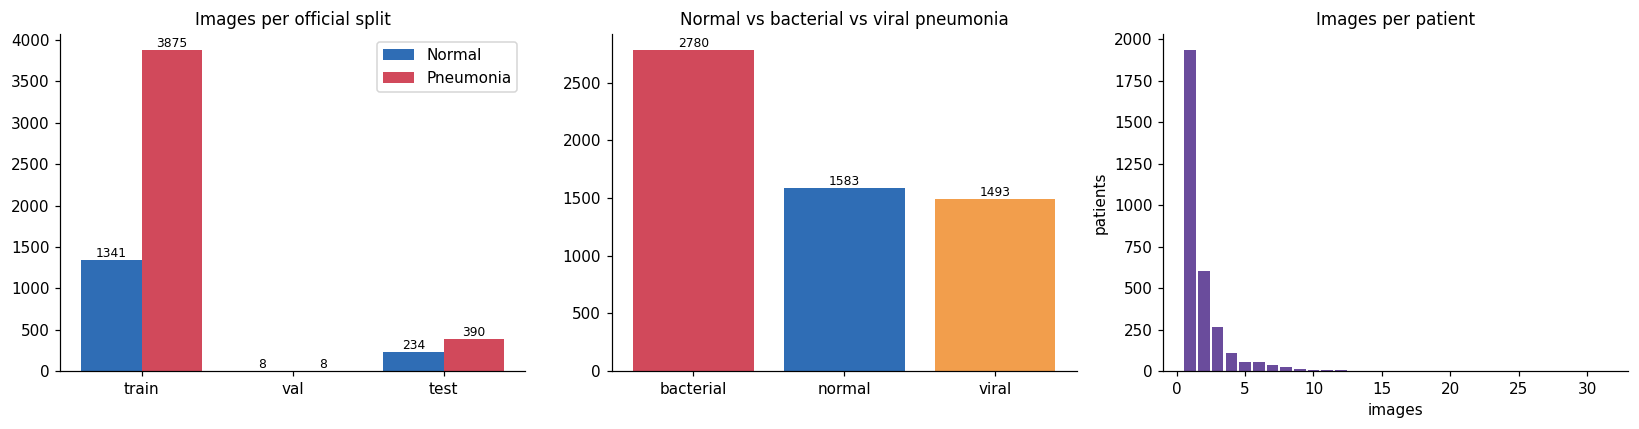

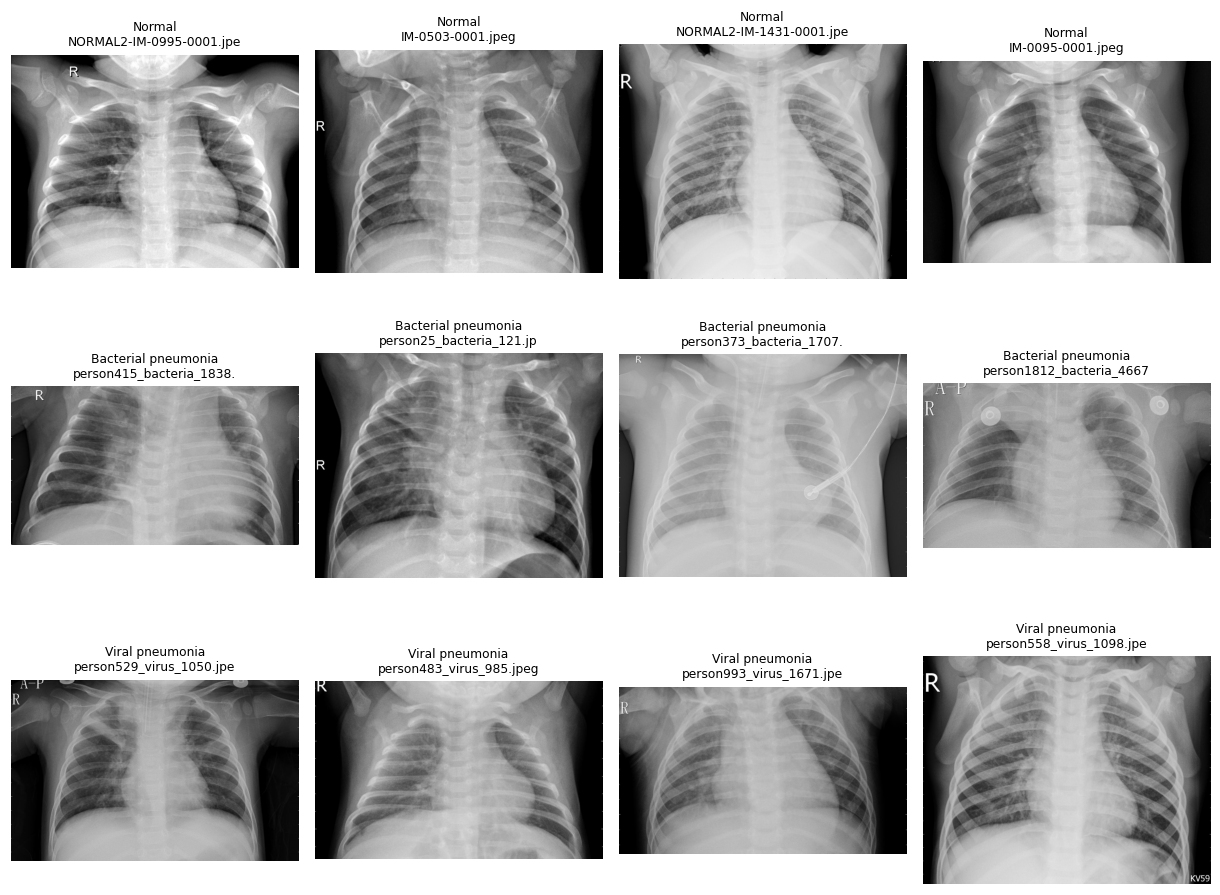

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ct = pd.crosstab(df["split"], df["class"]).reindex(columns=CLASS_NAMES, fill_value=0)
ct = ct.reindex([s for s in ["train", "val", "test"] if s in ct.index])
x = np.arange(len(ct))
b1 = axes[0].bar(x - 0.2, ct["Normal"], 0.4, color=C_NORMAL, label="Normal")
b2 = axes[0].bar(x + 0.2, ct["Pneumonia"], 0.4, color=C_PNEU, label="Pneumonia")
axes[0].bar_label(b1, fontsize=8)
axes[0].bar_label(b2, fontsize=8)
axes[0].set_xticks(x, ct.index)
axes[0].set_title("Images per official split")
axes[0].legend()

tc = df["type"].value_counts()
colors = {"normal": C_NORMAL, "bacterial": C_PNEU, "viral": C_VIRAL, "unknown": "grey"}
b = axes[1].bar(tc.index, tc.values, color=[colors[k] for k in tc.index])
axes[1].bar_label(b, fontsize=8)
axes[1].set_title("Normal vs bacterial vs viral pneumonia")

ipp = df.groupby("patient").size()
axes[2].hist(ipp, bins=np.arange(1, ipp.max() + 2) - 0.5, color="#6A4C9C", rwidth=0.85)
axes[2].set_title("Images per patient")
axes[2].set_xlabel("images")
axes[2].set_ylabel("patients")
fig.tight_layout()
save_fig(fig, "01_dataset_counts")

# example images (original resolution)
groups = [(k, t) for k, t in [("normal", "Normal"), ("bacterial", "Bacterial pneumonia"), ("viral", "Viral pneumonia")]
          if (df["type"] == k).any()]
n_show = 4
fig, axes = plt.subplots(len(groups), n_show, figsize=(2.8 * n_show, 2.9 * len(groups)))
axes = np.atleast_2d(axes)
for r, (k, title) in enumerate(groups):
    pick = df[df["type"] == k].sample(n=min(n_show, int((df["type"] == k).sum())), random_state=SEED)
    for c in range(n_show):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(pick):
            with Image.open(pick.iloc[c]["path"]) as im:
                ax.imshow(im.convert("L"), cmap="gray")
            ax.set_title(f"{title}\n{pick.iloc[c]['filename'][:24]}", fontsize=8)
fig.tight_layout()
save_fig(fig, "02_example_images")

## 3. Load all images into memory
Every image is converted to grayscale, its **black borders are removed** (outer rows and columns that are almost black),
**3% is trimmed from every edge**, and it is resized to 224×224 **once**.
In the v1 run, Normal images had about twice as many near-black (border) pixels as Pneumonia images, so the amount of border
was a possible shortcut. Section 3.1 measures this for the train and test folders.
The array (about 0.3 GB) is reused by every training run, which makes them much faster.

Loaded 5856 images -> (5856, 224, 224, 1), 294 MB in 32 s


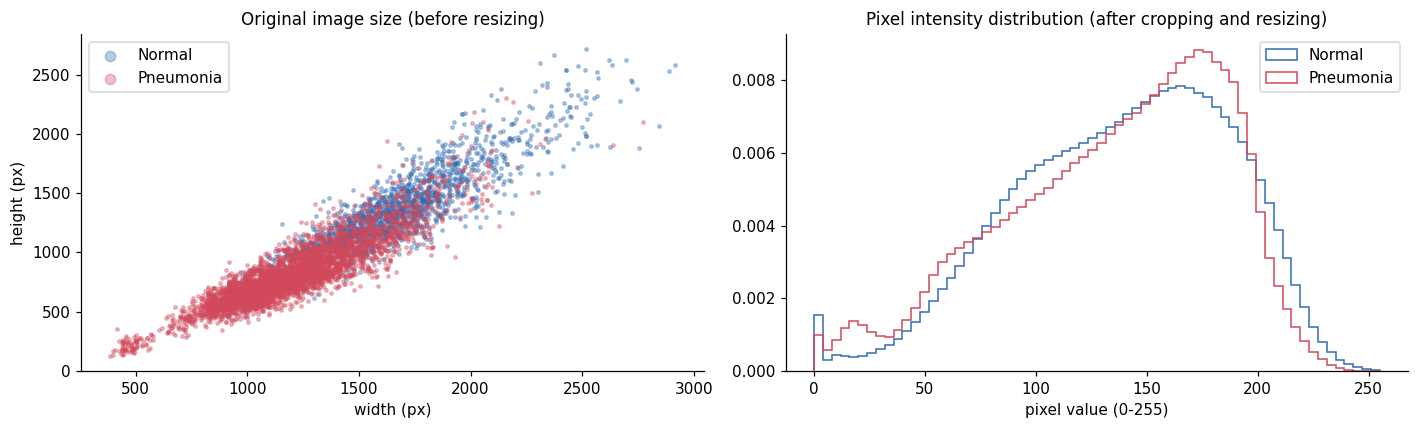

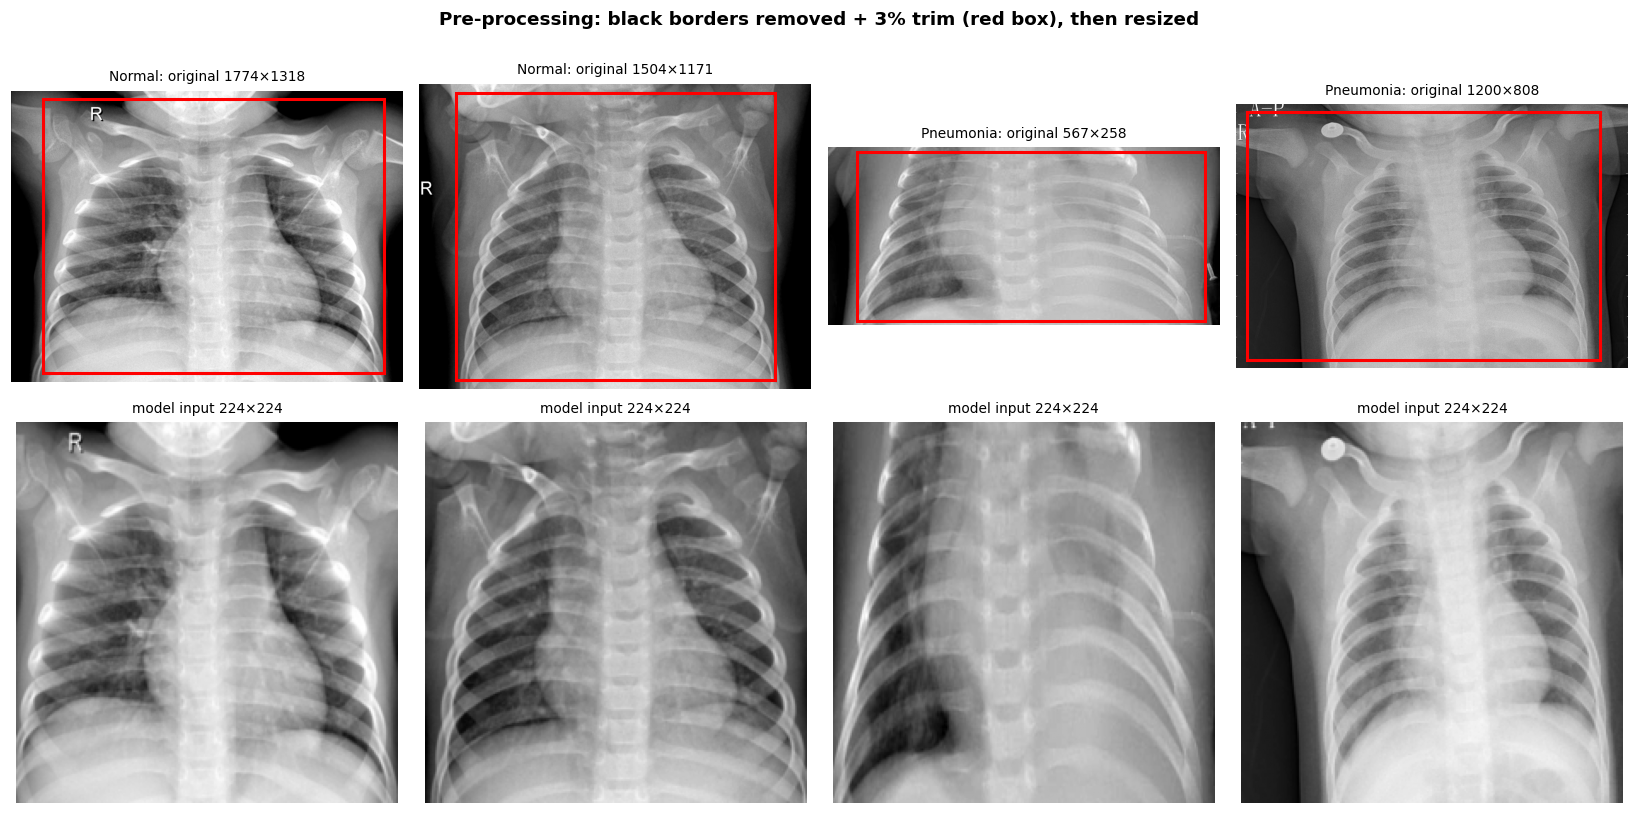

In [5]:
RESAMPLE = getattr(getattr(Image, "Resampling", Image), "BILINEAR")


def body_box(a):
    """Box (left, top, right, bottom) around the body of a grayscale image `a`:
    outer columns/rows that are almost black (black borders) are dropped, then CROP_MARGIN is trimmed from every edge."""
    h, w = a.shape
    box = []
    for prof, n in ((a.mean(axis=0), w), (a.mean(axis=1), h)):         # column means, then row means
        keep = np.flatnonzero(prof > 0.2 * np.percentile(prof, 95))     # "almost black" = below 20% of a bright line
        lo, hi = (int(keep[0]), int(keep[-1]) + 1) if len(keep) else (0, n)
        if hi - lo < 0.5 * n:                                           # something unusual: keep the full image
            lo, hi = 0, n
        m = int((hi - lo) * CROP_MARGIN)
        box.append((lo + m, hi - m))
    (l, r), (t, b) = box
    return l, t, r, b


def load_one(path):
    with Image.open(path) as im:
        size = im.size                                    # original (width, height)
        im.draft("L", (IMG_SIZE * 2, IMG_SIZE * 2))       # fast JPEG down-scaling while decoding
        im = im.convert("L")
        a = np.asarray(im)
        dark = float((a < 10).mean())                     # share of near-black pixels before cropping
        im = im.crop(body_box(a)).resize((IMG_SIZE, IMG_SIZE), RESAMPLE)
        return np.asarray(im, dtype=np.uint8), size, dark


t0 = time.time()
with ThreadPoolExecutor(max_workers=max(4, os.cpu_count() or 4)) as pool:
    loaded = list(pool.map(load_one, df["path"].tolist()))
X_all = np.stack([r[0] for r in loaded])[..., None]          # (N, 224, 224, 1) uint8
df["orig_w"] = [r[1][0] for r in loaded]
df["orig_h"] = [r[1][1] for r in loaded]
df["border_share"] = [r[2] for r in loaded]
y_all = df["label"].to_numpy().astype(np.int32)
del loaded
gc.collect()
print(f"Loaded {X_all.shape[0]} images -> {X_all.shape}, {X_all.nbytes / 1e6:.0f} MB in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rng = np.random.default_rng(SEED)
for lab, col in [(0, C_NORMAL), (1, C_PNEU)]:
    sel = df["label"] == lab
    axes[0].scatter(df.loc[sel, "orig_w"], df.loc[sel, "orig_h"], s=5, alpha=0.35, color=col, label=CLASS_NAMES[lab])
    idx = np.where(y_all == lab)[0]
    idx = rng.choice(idx, size=min(400, len(idx)), replace=False)
    axes[1].hist(X_all[idx].ravel(), bins=64, density=True, histtype="step", lw=1.8, color=col, label=CLASS_NAMES[lab])
axes[0].set_title("Original image size (before resizing)")
axes[0].set_xlabel("width (px)")
axes[0].set_ylabel("height (px)")
axes[0].legend(markerscale=3)
axes[1].set_title("Pixel intensity distribution (after cropping and resizing)")
axes[1].set_xlabel("pixel value (0-255)")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "03_image_sizes_and_intensity")

# what the crop keeps (red box) and the final 224x224 input
from matplotlib.patches import Rectangle
demo = pd.concat([df[df["label"] == 0].sample(2, random_state=SEED), df[df["label"] == 1].sample(2, random_state=SEED)])
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for c, (i, row) in enumerate(demo.iterrows()):
    with Image.open(row["path"]) as im:
        full = im.convert("L")
    l, t, r, b = body_box(np.asarray(full))
    axes[0, c].imshow(full, cmap="gray")
    axes[0, c].add_patch(Rectangle((l, t), r - l, b - t, fill=False, ec="red", lw=2))
    axes[0, c].set_title(f"{row['class']}: original {full.size[0]}×{full.size[1]}", fontsize=9)
    axes[1, c].imshow(X_all[i, ..., 0], cmap="gray")
    axes[1, c].set_title(f"model input {IMG_SIZE}×{IMG_SIZE}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
fig.suptitle("Pre-processing: black borders removed + 3% trim (red box), then resized", fontweight="bold")
fig.tight_layout()
save_fig(fig, "03b_preprocessing_examples")

### 3.1 Dataset bias check
Are there differences between the classes, or between the train and test folders, that have nothing to do with the lungs?
We compare image size, black-border share (before cropping), brightness and contrast, and test whether these simple properties **alone** can predict the label.
If they can, a CNN may learn them as a shortcut. This table and figure are useful for the *Dataset* or *Discussion* section of the paper.

Median values per folder and class (border share = near-black pixels before cropping;
brightness/contrast measured after pre-processing, 0-1 scale):


orig_w  orig_h  border_share  brightness  contrast
folder    class                                                        
test      Normal     1762.0  1317.5         0.075       0.547     0.180
          Pneumonia  1111.0   736.0         0.028       0.521     0.172
train+val Normal     1638.0  1325.0         0.089       0.545     0.180
          Pneumonia  1168.0   776.0         0.033       0.540     0.172

,AUC inside train folder (5-fold),AUC on official test folder
features used (no pixels of the lungs),,
image size only,0.918,0.912
black-border share only,0.701,0.614
brightness + contrast only,0.597,0.649
all of the above,0.925,0.911


AUC 0.5 = useless, 1.0 = perfect. A high AUC here means the label can be guessed without looking at the lungs,
and a big drop from the train folder to the test folder means such a shortcut will not transfer to the test set.


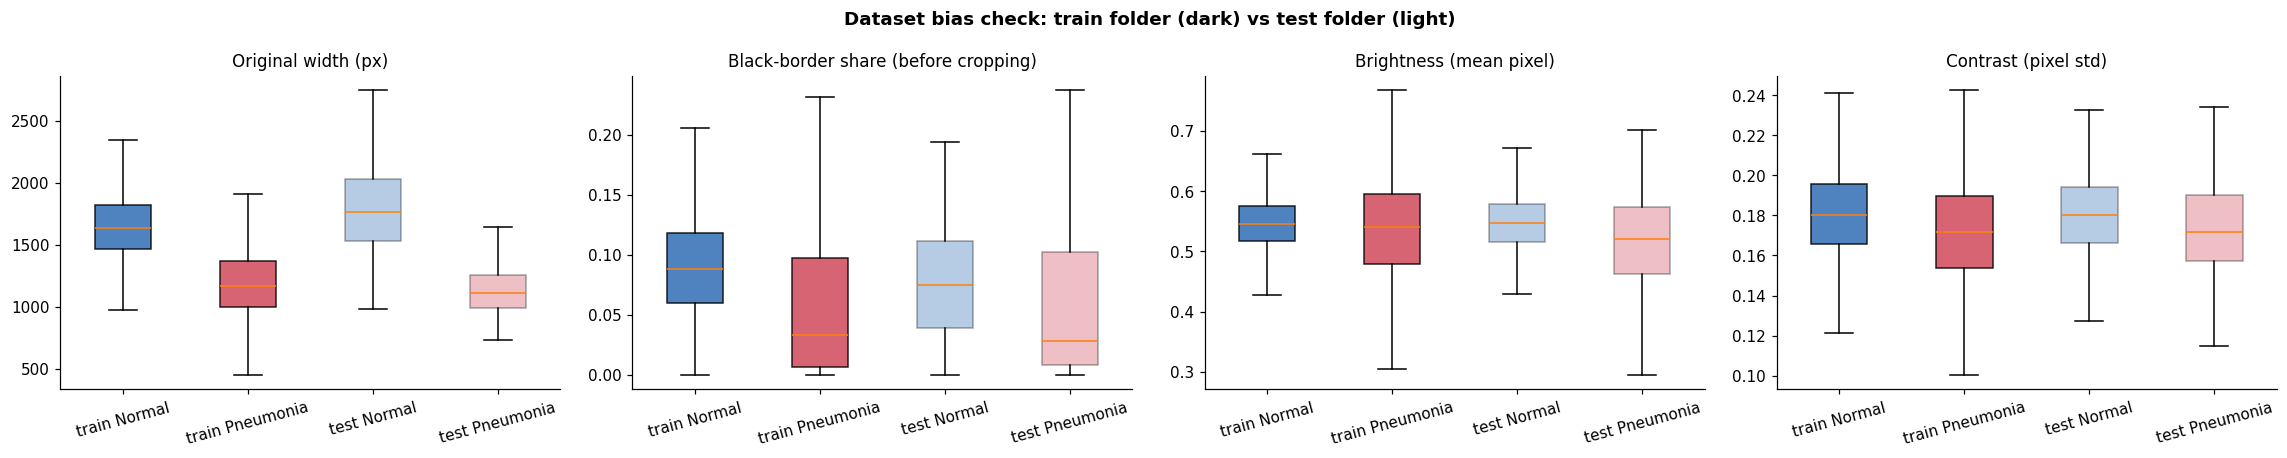

In [6]:
bright, contr = np.empty(len(df)), np.empty(len(df))
for s in range(0, len(df), 512):                               # in chunks to save memory
    blk = X_all[s:s + 512, ..., 0].reshape(-1, IMG_SIZE * IMG_SIZE).astype(np.float32) / 255.0
    bright[s:s + 512], contr[s:s + 512] = blk.mean(axis=1), blk.std(axis=1)
df["brightness"], df["contrast"] = bright, contr
df["folder"] = np.where(df["split"] == "test", "test", "train+val")
df["log_w"], df["log_h"] = np.log(df["orig_w"]), np.log(df["orig_h"])

medians = df.groupby(["folder", "class"])[["orig_w", "orig_h", "border_share", "brightness", "contrast"]].median().round(3)
print("Median values per folder and class (border share = near-black pixels before cropping;\n"
      "brightness/contrast measured after pre-processing, 0-1 scale):")
display(medians)
save_table(medians, "bias_check_medians", index=True)

tr_m, te_m = (df["split"] != "test").to_numpy(), (df["split"] == "test").to_numpy()
bias_rows = []
for name, cols in [("image size only", ["log_w", "log_h"]),
                   ("black-border share only", ["border_share"]),
                   ("brightness + contrast only", ["brightness", "contrast"]),
                   ("all of the above", ["log_w", "log_h", "border_share", "brightness", "contrast"])]:
    lr = LogisticRegression(max_iter=2000, class_weight="balanced")
    p_in = cross_val_predict(lr, df.loc[tr_m, cols], y_all[tr_m], cv=5, method="predict_proba")[:, 1]
    lr.fit(df.loc[tr_m, cols], y_all[tr_m])
    p_out = lr.predict_proba(df.loc[te_m, cols])[:, 1]
    bias_rows.append({"features used (no pixels of the lungs)": name,
                      "AUC inside train folder (5-fold)": roc_auc_score(y_all[tr_m], p_in),
                      "AUC on official test folder": roc_auc_score(y_all[te_m], p_out)})
bias_table = pd.DataFrame(bias_rows).set_index("features used (no pixels of the lungs)").round(3)
display(bias_table)
save_table(bias_table, "bias_check_shortcut_auc", index=True)
print("AUC 0.5 = useless, 1.0 = perfect. A high AUC here means the label can be guessed without looking at the lungs,\n"
      "and a big drop from the train folder to the test folder means such a shortcut will not transfer to the test set.")

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
groups = [("train+val", "Normal"), ("train+val", "Pneumonia"), ("test", "Normal"), ("test", "Pneumonia")]
names = ["train Normal", "train Pneumonia", "test Normal", "test Pneumonia"]
for ax, col, title in zip(axes, ["orig_w", "border_share", "brightness", "contrast"],
                          ["Original width (px)", "Black-border share (before cropping)",
                           "Brightness (mean pixel)", "Contrast (pixel std)"]):
    data = [df.loc[(df["folder"] == f) & (df["class"] == c), col].to_numpy() for f, c in groups]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    for patch, (f, c) in zip(bp["boxes"], groups):
        patch.set_facecolor(C_NORMAL if c == "Normal" else C_PNEU)
        patch.set_alpha(0.35 if f == "test" else 0.85)
    ax.set_xticks(np.arange(1, 5), names, rotation=15)
    ax.set_title(title)
fig.suptitle("Dataset bias check: train folder (dark) vs test folder (light)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "03c_dataset_bias_check")

## 4. Official protocol: train / validation / test
- **Test:** the official 624-image `test/` folder. It is **never** used during training.
- **Train + validation:** the official `train/` folder plus the 16-image `val/` folder, split **by patient**: 90% train, 10% validation.
  (The 16-image `val/` folder alone is far too small to guide training.)
- **Class weights:** Normal images are rarer, so a mistake on a Normal image counts more during training.
- **Augmentation (training only):** rotation ±15°, zoom in up to 20% / out up to 10% (height and width separately), shift ±10%, brightness ±20%, contrast ±30%;
  in half of the batches the image is blurred by lowering its resolution (50–100%) and scaling it back;
  random noise is added. No flips, because a mirrored chest is not realistic.

In [7]:
def patient_holdout(sub_df, frac, seed):
    """Split rows so that every patient is on one side only (and both sides keep the class balance)."""
    n_splits = max(2, int(round(1 / frac)))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    tr, va = next(sgkf.split(sub_df, sub_df["label"], groups=sub_df["patient"]))
    return sub_df.iloc[tr], sub_df.iloc[va]


def class_weights(labels):
    counts = np.bincount(labels, minlength=2)
    return {i: float(len(labels) / (2 * counts[i])) for i in range(2)}


pool_df = df[df["split"].isin(["train", "val"])]
test_df = df[df["split"] == "test"]
train_df, val_df = patient_holdout(pool_df, VAL_FRACTION, SEED)
assert not set(train_df["patient"]) & set(val_df["patient"]), "patient leak between train and validation"

tr_idx, va_idx, te_idx = (train_df.index.to_numpy(), val_df.index.to_numpy(), test_df.index.to_numpy())
CLASS_WEIGHT = class_weights(y_all[tr_idx])

split_table = pd.DataFrame(
    {name: [len(d), int((d["label"] == 0).sum()), int((d["label"] == 1).sum()), d["patient"].nunique()]
     for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]},
    index=["images", "Normal", "Pneumonia", "patients"]).T
display(split_table)
save_table(split_table, "official_split", index=True)
print("Class weights:", {CLASS_NAMES[k]: round(v, 3) for k, v in CLASS_WEIGHT.items()})

,images,Normal,Pneumonia,patients
train,4725,1211,3514,2577
validation,507,138,369,284
test,624,234,390,427


Class weights: {'Normal': 1.951, 'Pneumonia': 0.672}


I0000 00:00:1790238064.307379      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790238064.310441      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


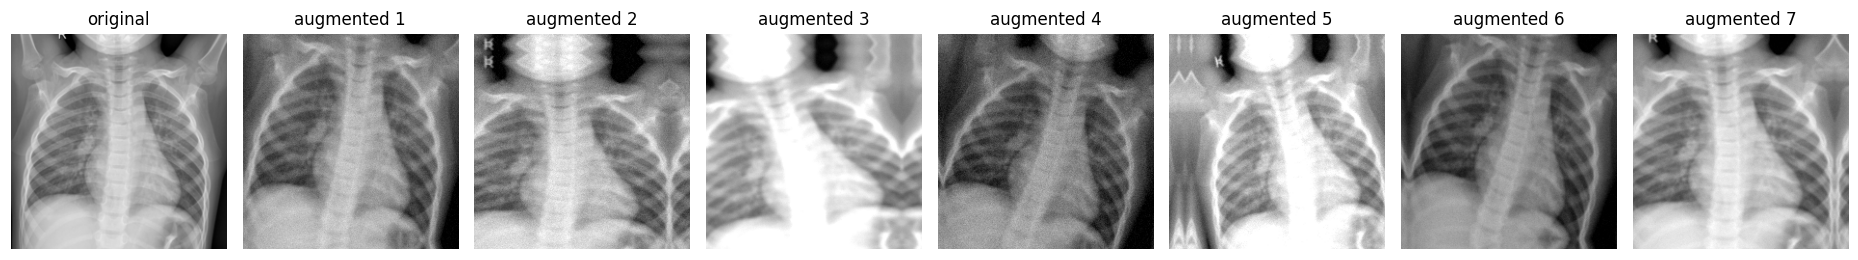

In [8]:
augmenter = keras.Sequential([
    layers.RandomRotation(15 / 360, fill_mode="reflect", seed=SEED),
    layers.RandomZoom(height_factor=(-0.20, 0.10), width_factor=(-0.20, 0.10),   # negative = zoom in
                      fill_mode="reflect", seed=SEED),
    layers.RandomTranslation(0.10, 0.10, fill_mode="reflect", seed=SEED),
    layers.RandomBrightness(0.20, value_range=(0.0, 1.0), seed=SEED),
    layers.RandomContrast(0.30, seed=SEED),
], name="augmentation")

tta_augmenter = keras.Sequential([                       # milder, used only for test-time augmentation
    layers.RandomRotation(5 / 360, fill_mode="reflect", seed=SEED + 1),
    layers.RandomZoom(0.05, fill_mode="reflect", seed=SEED + 1),
    layers.RandomTranslation(0.05, 0.05, fill_mode="reflect", seed=SEED + 1),
], name="tta_augmentation")


def random_resolution(x):
    """Lower the resolution of a batch (50-100%) and scale it back, so image sharpness is not a usable cue."""
    s = tf.random.uniform([], 0.5, 1.0)
    size = tf.cast(tf.round(IMG_SIZE * s), tf.int32)
    small = tf.image.resize(x, tf.stack([size, size]), method="bilinear", antialias=True)
    return tf.image.resize(small, [IMG_SIZE, IMG_SIZE], method="bilinear")


def train_map(x, y):
    x = augmenter(x, training=True)
    x = tf.cond(tf.random.uniform([]) < 0.5, lambda: random_resolution(x), lambda: x)
    x = x + tf.random.normal(tf.shape(x), stddev=tf.random.uniform([], 0.0, 0.03))     # random noise
    return tf.clip_by_value(x, 0.0, 1.0), y


def to_float(idx):
    return X_all[idx].astype(np.float32) / 255.0


def make_ds(idx, training, seed=SEED):
    """tf.data pipeline from the in-memory array; idx = row numbers of df."""
    ds = tf.data.Dataset.from_tensor_slices((X_all[idx], y_all[idx].astype(np.float32)))
    if training:
        ds = ds.shuffle(len(idx), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(train_map, num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


def make_tta_ds(idx):
    """One randomly shifted/rotated/zoomed view of every image in idx (images only, no labels)."""
    ds = tf.data.Dataset.from_tensor_slices(X_all[idx]).batch(BATCH_SIZE)
    ds = ds.map(lambda x: tta_augmenter(tf.cast(x, tf.float32) / 255.0, training=True), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


example = to_float(tr_idx[:1])
fig, axes = plt.subplots(1, 8, figsize=(17, 2.5))
axes[0].imshow(example[0, ..., 0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("original")
for i in range(1, 8):
    aug = np.asarray(train_map(tf.constant(example), tf.constant([0.0]))[0])
    axes[i].imshow(aug[0, ..., 0], cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(f"augmented {i}")
for a in axes:
    a.axis("off")
fig.tight_layout()
save_fig(fig, "04_augmentation_examples")

## 5. DSRA-Net model
The layer names match the architecture figure:

| Part in the figure | Layers | Output size |
|---|---|---|
| Input normalisation (new in v2, no weights) | `input_std`: each image minus its own mean, divided by its own standard deviation | 224×224×1 |
| Stem | `stem_conv` 3×3 (32) → `stem_bn` → `stem_relu` → `stem_pool` | 112×112×32 |
| **(b) DSG block** | branch A `dsg_A_*` (3×3) and branch B `dsg_B_*` (5×5) → gate `dsg_gate` → `dsg_out` → `dsg_pool` | 56×56×32 |
| **(c) Res-SE 1, 2, 3** | `rsX_c1_*` → `rsX_c2_*` → **(d)** `rsX_se_*` → + shortcut `rsX_short_*` → `rsX_out` → `rsX_pool` | 28×28×64, 14×14×128, 7×7×256 |
| Head | `head_gap` → `head_drop1` (0.5) → `head_fc` (128) → `head_drop2` (0.3) → `output` (sigmoid) | 1 |

The gate is computed as `Z = B + g·(A − B)`, which is exactly `Z = g·A + (1 − g)·B`.

In [9]:
BN_MOMENTUM = 0.9   # running BN statistics settle faster than with the Keras default (0.99)


class PerImageStandardization(layers.Layer):
    """Subtract each image's own mean and divide by its own standard deviation (no trainable weights)."""

    def call(self, x):
        mean = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
        std = tf.math.reduce_std(x, axis=[1, 2, 3], keepdims=True)
        return (x - mean) / (std + 1e-6)


def conv_bn_relu(x, filters, k, name):
    x = layers.Conv2D(filters, k, padding="same", use_bias=False, kernel_initializer="he_normal",
                      kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_conv")(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_bn")(x)
    return layers.Activation("relu", name=f"{name}_relu")(x)


def dsg_block(x, filters, name="dsg"):
    """(b) Dual-Scale Gate block: 3x3 and 5x5 branches mixed by a learned per-channel gate g."""
    a = conv_bn_relu(x, filters, 3, f"{name}_A")                          # branch A: fine detail
    b = conv_bn_relu(x, filters, 5, f"{name}_B")                          # branch B: wider patch
    u = layers.Add(name=f"{name}_fuse")([a, b])                           # A + B
    s = layers.GlobalAveragePooling2D(name=f"{name}_squeeze")(u)
    g = layers.Dense(filters, activation="sigmoid", kernel_regularizer=keras.regularizers.l2(L2_WEIGHT),
                     name=f"{name}_gate")(s)                              # g in (0, 1), one per channel
    g4 = layers.Reshape((1, 1, filters), name=f"{name}_gate_reshape")(g)
    diff = layers.Subtract(name=f"{name}_diff")([a, b])                   # A - B
    gd = layers.Multiply(name=f"{name}_gated_diff")([diff, g4])           # g * (A - B)
    return layers.Add(name=f"{name}_out")([b, gd])                        # Z = g*A + (1-g)*B


def se_block(x, filters, name, ratio=8):
    """(d) Squeeze-and-Excitation: learn one weight (0-1) per channel and rescale the channels."""
    s = layers.GlobalAveragePooling2D(name=f"{name}_squeeze")(x)
    s = layers.Dense(max(filters // ratio, 4), activation="relu",
                     kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_fc1")(s)
    w = layers.Dense(filters, activation="sigmoid",
                     kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_weights")(s)
    w4 = layers.Reshape((1, 1, filters), name=f"{name}_reshape")(w)
    return layers.Multiply(name=f"{name}_scale")([x, w4])


def res_se_block(x, filters, name):
    """(c) Residual block with SE attention and a 1x1 projection shortcut."""
    y = conv_bn_relu(x, filters, 3, f"{name}_c1")
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_initializer="he_normal",
                      kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_c2_conv")(y)
    y = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_c2_bn")(y)
    y = se_block(y, filters, f"{name}_se")
    sc = layers.Conv2D(filters, 1, padding="same", use_bias=False, kernel_initializer="he_normal",
                       kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_short_conv")(x)
    sc = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_short_bn")(sc)
    out = layers.Add(name=f"{name}_add")([y, sc])
    return layers.Activation("relu", name=f"{name}_out")(out)


def build_dsranet(input_shape=(IMG_SIZE, IMG_SIZE, 1)):
    inp = keras.Input(shape=input_shape, name="input_cxr")
    x = PerImageStandardization(name="input_std")(inp)
    x = conv_bn_relu(x, 32, 3, "stem")
    x = layers.MaxPooling2D(2, name="stem_pool")(x)
    x = dsg_block(x, 32, "dsg")
    x = layers.MaxPooling2D(2, name="dsg_pool")(x)
    for i, c in enumerate([64, 128, 256], start=1):
        x = res_se_block(x, c, f"rs{i}")
        x = layers.MaxPooling2D(2, name=f"rs{i}_pool")(x)
    x = layers.GlobalAveragePooling2D(name="head_gap")(x)
    x = layers.Dropout(0.5, name="head_drop1")(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name="head_fc")(x)
    x = layers.Dropout(0.3, name="head_drop2")(x)
    out = layers.Dense(1, activation="sigmoid", name="output")(x)
    return keras.Model(inp, out, name="DSRA_Net")


model = build_dsranet()
model.summary(line_length=110)

Model: "DSRA_Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                   ┃ Output Shape              ┃          Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_cxr (InputLayer)         │ (None, 224, 224, 1)       │                0 │ -                          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ input_std                      │ (None, 224, 224, 1)       │                0 │ input_cxr[0][0]            │
│ (PerImageStandardization)      │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ stem_conv (Conv2D)             │ (None, 224, 224, 32)      │              288 │ input_std[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ stem_bn (BatchNormalization)   │ (None, 224, 224, 32)      │              128 │ stem_conv[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ stem_relu (Activation)         │ (None, 224, 224, 32)      │                0 │ stem_bn[0][0]              │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ stem_pool (MaxPooling2D)       │ (None, 112, 112, 32)      │                0 │ stem_relu[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_B_conv (Conv2D)            │ (None, 112, 112, 32)      │           25,600 │ stem_pool[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_A_conv (Conv2D)            │ (None, 112, 112, 32)      │            9,216 │ stem_pool[0][0]            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_B_bn (BatchNormalization)  │ (None, 112, 112, 32)      │              128 │ dsg_B_conv[0][0]           │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_A_bn (BatchNormalization)  │ (None, 112, 112, 32)      │              128 │ dsg_A_conv[0][0]           │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_B_relu (Activation)        │ (None, 112, 112, 32)      │                0 │ dsg_B_bn[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_A_relu (Activation)        │ (None, 112, 112, 32)      │                0 │ dsg_A_bn[0][0]             │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_fuse (Add)                 │ (None, 112, 112, 32)      │                0 │ dsg_A_relu[0][0],          │
│                                │                           │                  │ dsg_B_relu[0][0]           │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_squeeze                    │ (None, 32)                │                0 │ dsg_fuse[0][0]             │
│ (GlobalAveragePooling2D)       │                           │                  │                            │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ dsg_gate (Dense)               │ (None, 32)                │            1,056 │ dsg_squeeze[0][0]          │
├────────────────────────────────┼───────────────────────────┼──────────────────┼────────────────────────────┤
│ ds

 Total params: 1,301,177 (4.96 MB)

 Trainable params: 1,298,297 (4.95 MB)

 Non-trainable params: 2,880 (11.25 KB)

### 5.1 Size of each block (parameters and computation)

,params,MACs,params %,MACs %
Stem,416,14450688,0.0,1.5
(b) DSG,36128,436732928,2.8,44.1
(c) Res-SE 1,59208,179831808,4.6,18.2
(c) Res-SE 2,235152,179834880,18.1,18.2
(c) Res-SE 3,937248,179847168,72.0,18.2
Head,32896,32768,2.5,0.0
Output,129,128,0.0,0.0


Total parameters: 1,301,177  |  compute: 0.99 GMACs (~1.98 GFLOPs) per 224x224 image


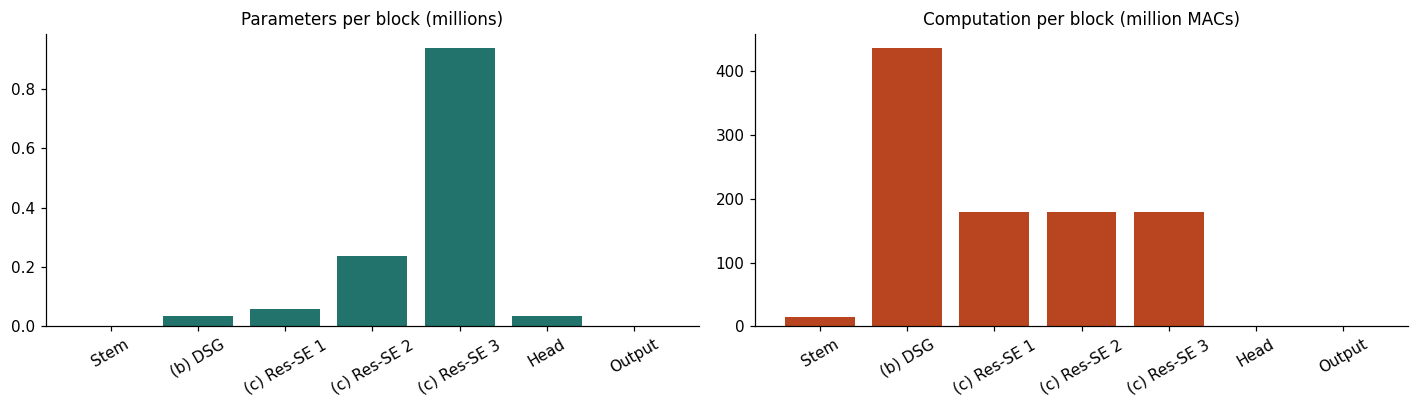

Layer graph saved to figures/model_graph.png


In [10]:
BLOCKS = ["stem", "dsg", "rs1", "rs2", "rs3", "head", "output"]
BLOCK_LABEL = {"stem": "Stem", "dsg": "(b) DSG", "rs1": "(c) Res-SE 1", "rs2": "(c) Res-SE 2",
               "rs3": "(c) Res-SE 3", "head": "Head", "output": "Output"}


def layer_costs(m):
    rows = []
    for lyr in m.layers:
        macs = 0
        if isinstance(lyr, layers.Conv2D):
            out_shape = lyr.output.shape
            macs = int(out_shape[1]) * int(out_shape[2]) * int(np.prod([int(v) for v in lyr.kernel.shape]))
        elif isinstance(lyr, layers.Dense):
            macs = int(np.prod([int(v) for v in lyr.kernel.shape]))
        rows.append({"layer": lyr.name, "block": lyr.name.split("_")[0], "params": int(lyr.count_params()), "MACs": macs})
    return pd.DataFrame(rows)


costs = layer_costs(model)
per_block = costs.groupby("block")[["params", "MACs"]].sum().reindex(BLOCKS).fillna(0).astype(int)
per_block.index = [BLOCK_LABEL[b] for b in per_block.index]
per_block["params %"] = (100 * per_block["params"] / per_block["params"].sum()).round(1)
per_block["MACs %"] = (100 * per_block["MACs"] / per_block["MACs"].sum()).round(1)
display(per_block)
save_table(per_block, "params_and_macs_per_block", index=True)
TOTAL_PARAMS = int(model.count_params())
TOTAL_GFLOPS = 2 * costs["MACs"].sum() / 1e9
print(f"Total parameters: {TOTAL_PARAMS:,}  |  compute: {costs['MACs'].sum() / 1e9:.2f} GMACs "
      f"(~{TOTAL_GFLOPS:.2f} GFLOPs) per 224x224 image")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(per_block.index, per_block["params"] / 1e6, color="#22736C")
axes[0].set_title("Parameters per block (millions)")
axes[1].bar(per_block.index, per_block["MACs"] / 1e6, color="#B8451F")
axes[1].set_title("Computation per block (million MACs)")
for a in axes:
    a.tick_params(axis="x", rotation=30)
fig.tight_layout()
save_fig(fig, "05_params_and_macs_per_block")

try:
    keras.utils.plot_model(model, to_file=os.path.join(FIG_DIR, "model_graph.png"), show_shapes=True, dpi=70)
    print("Layer graph saved to figures/model_graph.png")
except Exception as e:
    print("plot_model skipped (needs pydot + graphviz):", str(e)[:100])

## 6. Train DSRA-Net (official split)
Adam (learning rate 0.001), binary cross-entropy with class weights and label smoothing 0.1, up to 60 epochs.
The learning rate is halved when the validation loss stops improving, training stops early after 10 epochs without improvement,
and the weights from the **best epoch** (lowest validation loss) are kept.
`N_SEEDS` models are trained with different random seeds; their predictions are averaged in section 7.
The model with the lowest validation loss is used for the block-by-block analysis (sections 8–11).

In [11]:
class LRRecorder(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.lrs = []

    def on_epoch_begin(self, epoch, logs=None):
        self.lrs.append(float(np.asarray(self.model.optimizer.learning_rate)))


def compile_model(m):
    m.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
              loss=keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING),
              metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc"),
                       keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")],
              jit_compile=False)
    return m


def train_model(m, train_rows, val_rows, class_weight, run_name, epochs=EPOCHS, verbose=2, seed=SEED):
    ckpt = os.path.join(MODEL_DIR, f"{run_name}.weights.h5")
    lr_rec = LRRecorder()
    callbacks = [lr_rec,
                 keras.callbacks.EarlyStopping(monitor="val_loss", patience=ES_PATIENCE,
                                               restore_best_weights=True, verbose=1),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE,
                                                   min_lr=1e-6, verbose=1),
                 keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True,
                                                 save_weights_only=True, verbose=0)]
    t0 = time.time()
    hist = m.fit(make_ds(train_rows, True, seed=seed), validation_data=make_ds(val_rows, False), epochs=epochs,
                 class_weight=class_weight, callbacks=callbacks, verbose=verbose)
    seconds = time.time() - t0
    if os.path.exists(ckpt):
        m.load_weights(ckpt)                     # weights of the best epoch
    h = pd.DataFrame(hist.history)
    h.insert(0, "epoch", np.arange(1, len(h) + 1))
    h["lr"] = lr_rec.lrs[:len(h)]
    return h, seconds


keras.backend.clear_session()
runs = []
for k in range(N_SEEDS):
    run_seed = SEED + 100 * k
    keras.utils.set_random_seed(run_seed)
    print(f"\n========== Official split: model {k + 1}/{N_SEEDS} (seed {run_seed}) ==========")
    m = compile_model(build_dsranet())
    h, sec = train_model(m, tr_idx, va_idx, CLASS_WEIGHT, f"dsranet_official_seed{k + 1}", seed=run_seed)
    save_table(h, f"training_history_seed{k + 1}")
    best_ep = int(h.loc[h["val_loss"].idxmin(), "epoch"])
    runs.append({"model": m, "history": h, "seconds": sec, "seed": run_seed, "best_epoch": best_ep,
                 "best_val_loss": float(h["val_loss"].min())})
    print(f"Model {k + 1}: {sec / 60:.1f} min, {len(h)} epochs, best epoch {best_ep}, "
          f"best validation loss {h['val_loss'].min():.4f}")

best_k = int(np.argmin([r["best_val_loss"] for r in runs]))
model, history = runs[best_k]["model"], runs[best_k]["history"]      # used for sections 8-11
train_seconds = sum(r["seconds"] for r in runs)
model.save(os.path.join(MODEL_DIR, "dsranet_official_best.keras"))
BEST_EPOCH = runs[best_k]["best_epoch"]
print(f"\n{N_SEEDS} model(s) trained in {train_seconds / 60:.1f} min; model {best_k + 1} has the lowest validation loss")


========== Official split: model 1/3 (seed 42) ==========
Epoch 1/60
148/148 - 43s - 293ms/step - accuracy: 0.8301 - auc: 0.9098 - loss: 0.7828 - precision: 0.9411 - recall: 0.8230 - val_accuracy: 0.4596 - val_auc: 0.9819 - val_loss: 1.5142 - val_precision: 1.0000 - val_recall: 0.2575 - learning_rate: 0.0010
Epoch 2/60
148/148 - 25s - 169ms/step - accuracy: 0.8906 - auc: 0.9546 - loss: 0.6600 - precision: 0.9655 - recall: 0.8845 - val_accuracy: 0.5010 - val_auc: 0.9865 - val_loss: 1.2859 - val_precision: 1.0000 - val_recall: 0.3144 - learning_rate: 0.0010
Epoch 3/60
148/148 - 26s - 173ms/step - accuracy: 0.9084 - auc: 0.9665 - loss: 0.5935 - precision: 0.9689 - recall: 0.9058 - val_accuracy: 0.8836 - val_auc: 0.9843 - val_loss: 0.5859 - val_precision: 0.9844 - val_recall: 0.8537 - learning_rate: 0.0010
Epoch 4/60
148/148 - 25s - 169ms/step - accuracy: 0.9096 - auc: 0.9700 - loss: 0.5536 - precision: 0.9696 - recall: 0.9069 - val_accuracy: 0.8225 - val_auc: 0.9887 - val_loss: 0.7127 - 

### 6.1 Training curves

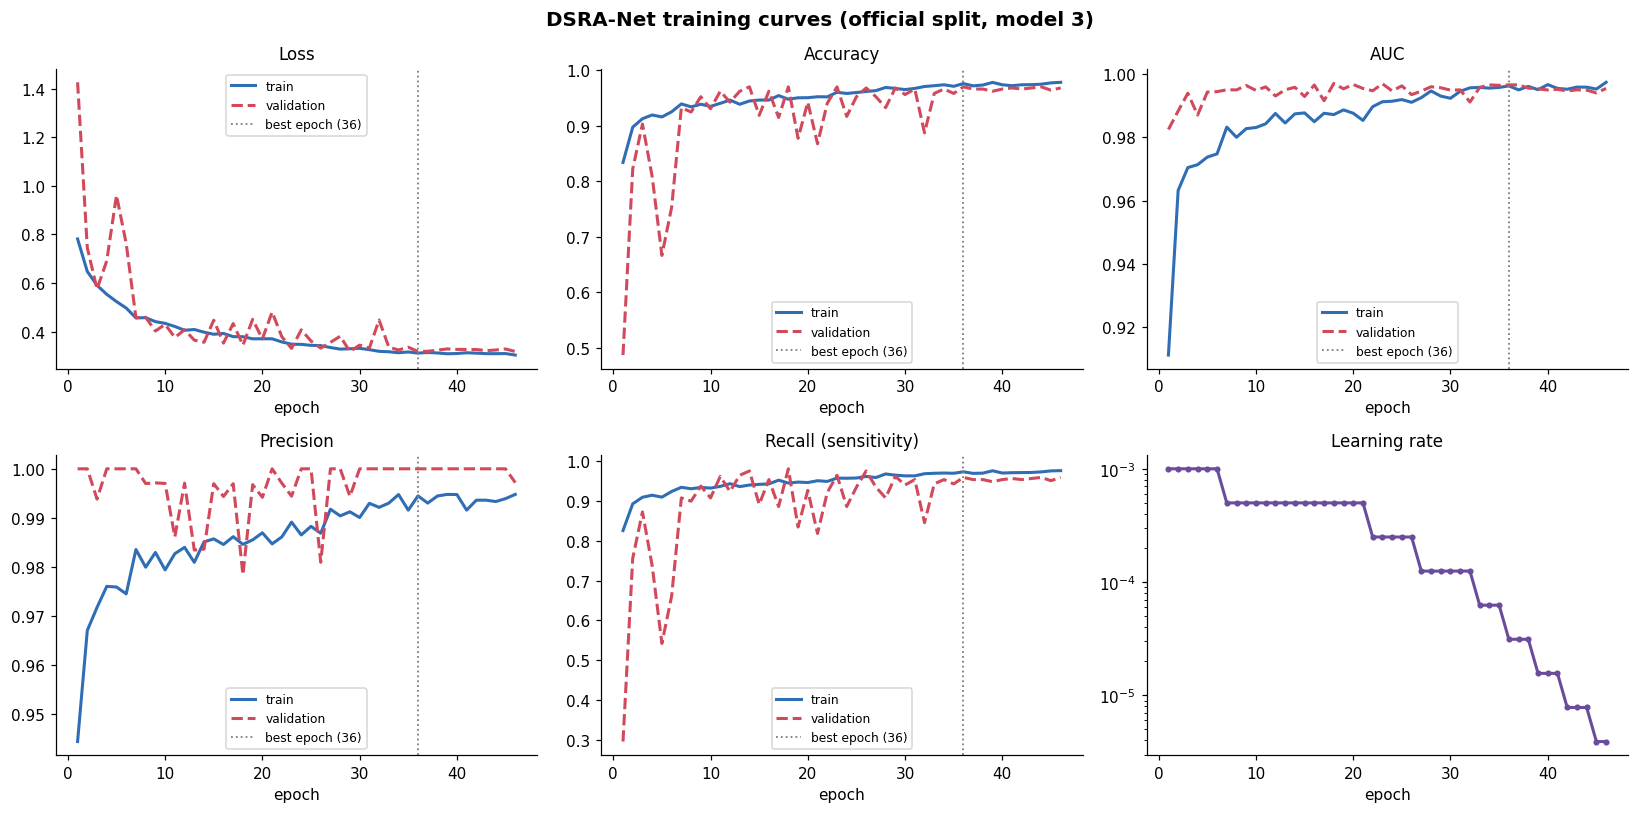

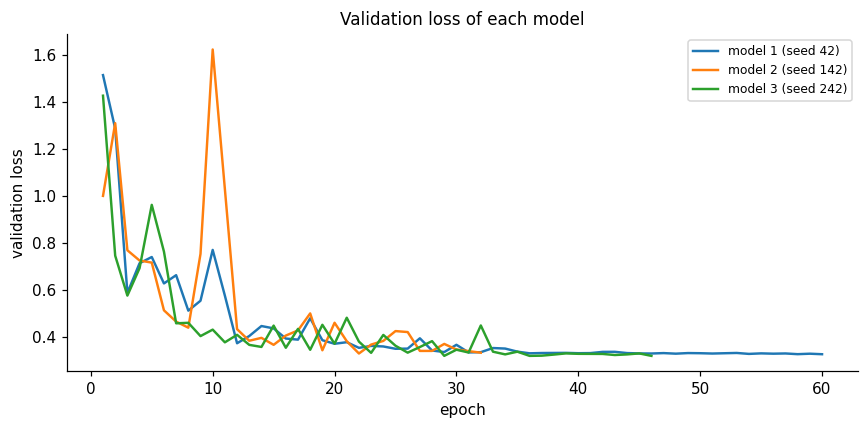

In [12]:
def plot_history(h, title, name):
    panels = [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC"),
              ("precision", "Precision"), ("recall", "Recall (sensitivity)")]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    best = int(h.loc[h["val_loss"].idxmin(), "epoch"])
    for ax, (k, lab) in zip(axes.ravel(), panels):
        if k in h:
            ax.plot(h["epoch"], h[k], color=C_NORMAL, lw=2, label="train")
        if f"val_{k}" in h:
            ax.plot(h["epoch"], h[f"val_{k}"], color=C_PNEU, lw=2, ls="--", label="validation")
        ax.axvline(best, color="grey", ls=":", lw=1.2, label=f"best epoch ({best})")
        ax.set_title(lab)
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8)
    ax = axes.ravel()[-1]
    ax.plot(h["epoch"], h["lr"], color="#6A4C9C", lw=2, marker="o", ms=3)
    ax.set_yscale("log")
    ax.set_title("Learning rate")
    ax.set_xlabel("epoch")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, name)


plot_history(history, f"DSRA-Net training curves (official split, model {best_k + 1})", "06_training_curves")

if len(runs) > 1:
    fig, ax = plt.subplots(figsize=(8, 4))
    for k, r in enumerate(runs):
        ax.plot(r["history"]["epoch"], r["history"]["val_loss"], lw=1.6, label=f"model {k + 1} (seed {r['seed']})")
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation loss")
    ax.set_title("Validation loss of each model")
    ax.legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, "06b_validation_loss_per_seed")

## 7. Results on the official test set (624 images)
Predictions are the **average of the `N_SEEDS` models**, each with **test-time augmentation** (the original image plus 4 slightly
rotated/shifted/zoomed copies). The main results use the fixed threshold **0.5**. A second column shows the threshold picked on the
**validation** set (Youden's J); nothing is tuned on the test set. 95% confidence intervals come from 1,000 bootstrap resamples.
A second table shows each single model and what TTA and averaging add, so single-model results can be reported too.

In [13]:
def binary_metrics(y_true, y_prob, thr=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a) / b if b else 0.0
    sens, spec, prec, npv = div(tp, tp + fn), div(tn, tn + fp), div(tp, tp + fp), div(tn, tn + fn)
    both = len(np.unique(y_true)) == 2
    return {"Accuracy": div(tp + tn, len(y_true)),
            "Balanced accuracy": (sens + spec) / 2,
            "Sensitivity (recall)": sens,
            "Specificity": spec,
            "Precision (PPV)": prec,
            "NPV": npv,
            "F1-score": div(2 * prec * sens, prec + sens),
            "MCC": float(matthews_corrcoef(y_true, y_pred)) if both else 0.0,
            "Cohen's kappa": float(cohen_kappa_score(y_true, y_pred)) if both else 0.0,
            "ROC-AUC": float(roc_auc_score(y_true, y_prob)) if both else float("nan"),
            "PR-AUC (AP)": float(average_precision_score(y_true, y_prob)) if both else float("nan"),
            "Log loss": float(log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7), labels=[0, 1])),
            "Brier score": float(brier_score_loss(y_true, y_prob)),
            "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn)}


def bootstrap_ci(y_true, y_prob, thr=THRESHOLD, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, y_prob = np.asarray(y_true).astype(int), np.asarray(y_prob, dtype=float)
    keys = ["Accuracy", "Sensitivity (recall)", "Specificity", "Precision (PPV)", "F1-score", "ROC-AUC"]
    vals = {k: [] for k in keys}
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        yt, yp = y_true[i], y_prob[i]
        if len(np.unique(yt)) < 2:
            continue
        pred = yp >= thr
        tp, tn = np.sum(pred & (yt == 1)), np.sum(~pred & (yt == 0))
        fp, fn = np.sum(pred & (yt == 0)), np.sum(~pred & (yt == 1))
        sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
        prec = tp / max(tp + fp, 1)
        vals["Accuracy"].append((tp + tn) / len(yt))
        vals["Sensitivity (recall)"].append(sens)
        vals["Specificity"].append(spec)
        vals["Precision (PPV)"].append(prec)
        vals["F1-score"].append(2 * prec * sens / max(prec + sens, 1e-12))
        vals["ROC-AUC"].append(roc_auc_score(yt, yp))
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in vals.items() if v}


def youden_threshold(y_true, y_prob):
    if len(np.unique(y_true)) < 2:
        return THRESHOLD
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return float(np.clip(thr[np.argmax(tpr - fpr)], 0.01, 0.99))


def predict_probs(m, idx, tta=USE_TTA):
    """Probability of pneumonia; with TTA it is the average over the original and TTA_VIEWS-1 shifted views."""
    views = [m.predict(make_ds(idx, False), verbose=0).ravel()]
    if tta:
        for _ in range(TTA_VIEWS - 1):
            views.append(m.predict(make_tta_ds(idx), verbose=0).ravel())
    return np.mean(views, axis=0)


y_val, y_test = y_all[va_idx], y_all[te_idx]
for r in runs:
    r["p_val"] = predict_probs(r["model"], va_idx)
    r["p_test"] = predict_probs(r["model"], te_idx)
    r["p_test_plain"] = predict_probs(r["model"], te_idx, tta=False) if USE_TTA else r["p_test"]
p_val = np.mean([r["p_val"] for r in runs], axis=0)            # average of all models = ensemble
p_test = np.mean([r["p_test"] for r in runs], axis=0)
y_pred = (p_test >= THRESHOLD).astype(int)
THR_VAL = youden_threshold(y_val, p_val)

m_test = binary_metrics(y_test, p_test)
m_test_val_thr = binary_metrics(y_test, p_test, THR_VAL)
ci = bootstrap_ci(y_test, p_test)

ENS_NAME = (f"ensemble of {len(runs)}" if len(runs) > 1 else "single model") + (" + TTA" if USE_TTA else "")
results = pd.DataFrame({f"Test ({ENS_NAME}), threshold 0.50": m_test,
                        f"Test, threshold {THR_VAL:.2f} (chosen on validation)": m_test_val_thr})
results["95% CI (threshold 0.50)"] = [f"{ci[k][0]:.4f} - {ci[k][1]:.4f}" if k in ci else "" for k in results.index]
display(results.round(4))
save_table(results.round(6), "test_metrics", index=True)

KEYS = ["Accuracy", "Sensitivity (recall)", "Specificity", "F1-score", "ROC-AUC"]


def mean_sd(vals):
    vals = np.asarray(vals, dtype=float)
    sd = vals.std(ddof=1) if len(vals) > 1 else 0.0
    return f"{vals.mean():.4f} ± {sd:.4f}"


per_model = pd.DataFrame([{"model": f"model {k + 1} (seed {r['seed']})",
                           **{kk: binary_metrics(y_test, r["p_test"])[kk] for kk in KEYS}}
                          for k, r in enumerate(runs)]).set_index("model")
print("Each single model on the official test set" + (" (with TTA)" if USE_TTA else "") + ":")
display(per_model.round(4))
save_table(per_model.round(6), "test_metrics_per_model", index=True)

steps = {"single model" + (", no TTA" if USE_TTA else ""): [r["p_test_plain"] for r in runs]}
if USE_TTA:
    steps["single model + TTA"] = [r["p_test"] for r in runs]
effect = {name: {k: mean_sd([binary_metrics(y_test, p)[k] for p in plist]) for k in KEYS} for name, plist in steps.items()}
if len(runs) > 1:
    effect[ENS_NAME] = {k: f"{m_test[k]:.4f}" for k in KEYS}
effect_df = pd.DataFrame(effect).T
print("What TTA and averaging add (single-model rows: mean ± std over the models):")
display(effect_df)
save_table(effect_df, "test_effect_of_tta_and_ensemble", index=True)

pd.DataFrame({"filename": df.loc[te_idx, "filename"].values, "type": df.loc[te_idx, "type"].values,
              "true": y_test, "prob_pneumonia": p_test, "pred": y_pred}).to_csv(
    os.path.join(TAB_DIR, "test_predictions.csv"), index=False)

,"Test (ensemble of 3 + TTA), threshold 0.50","Test, threshold 0.63 (chosen on validation)",95% CI (threshold 0.50)
Accuracy,0.9295,0.9343,0.9087 - 0.9487
Balanced accuracy,0.9077,0.9175,
Sensitivity (recall),0.9949,0.9846,0.9866 - 1.0000
Specificity,0.8205,0.8504,0.7662 - 0.8689
Precision (PPV),0.9023,0.9165,0.8747 - 0.9300
NPV,0.9897,0.9707,
F1-score,0.9463,0.9493,0.9308 - 0.9619
MCC,0.8528,0.8607,
Cohen's kappa,0.8442,0.8563,
ROC-AUC,0.9832,0.9832,0.9727 - 0.9909


Each single model on the official test set (with TTA):


,Accuracy,Sensitivity (recall),Specificity,F1-score,ROC-AUC
model,,,,,
model 1 (seed 42),0.9215,0.9974,0.7949,0.9407,0.9790
model 2 (seed 142),0.9135,0.9872,0.7906,0.9345,0.9796
model 3 (seed 242),0.9343,0.9821,0.8547,0.9492,0.9811


What TTA and averaging add (single-model rows: mean ± std over the models):


,Accuracy,Sensitivity (recall),Specificity,F1-score,ROC-AUC
"single model, no TTA",0.9284 ± 0.0094,0.9889 ± 0.0065,0.8276 ± 0.0345,0.9453 ± 0.0066,0.9777 ± 0.0008
single model + TTA,0.9231 ± 0.0105,0.9889 ± 0.0078,0.8134 ± 0.0358,0.9415 ± 0.0074,0.9799 ± 0.0011
ensemble of 3 + TTA,0.9295,0.9949,0.8205,0.9463,0.9832


### 7.1 Classification report and confusion matrix

              precision    recall  f1-score   support

      Normal     0.9897    0.8205    0.8972       234
   Pneumonia     0.9023    0.9949    0.9463       390

    accuracy                         0.9295       624
   macro avg     0.9460    0.9077    0.9218       624
weighted avg     0.9351    0.9295    0.9279       624



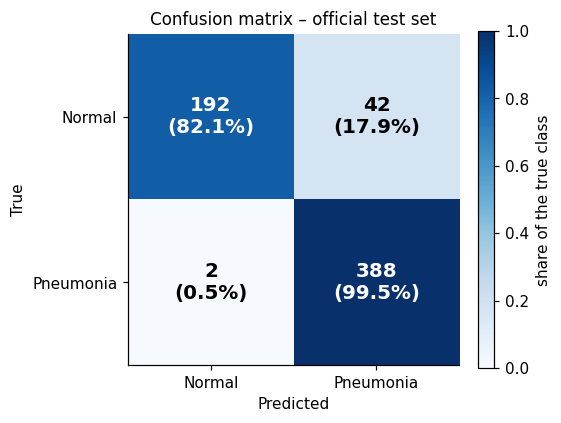

In [14]:
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=CLASS_NAMES, digits=4, zero_division=0))
report = pd.DataFrame(classification_report(y_test, y_pred, labels=[0, 1], target_names=CLASS_NAMES,
                                            digits=4, zero_division=0, output_dict=True)).T
save_table(report.round(6), "classification_report_test", index=True)


def plot_confusion(y_true, y_hat, title, name):
    cm = confusion_matrix(y_true, y_hat, labels=[0, 1])
    cmn = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(5, 4.3))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({100 * cmn[i, j]:.1f}%)", ha="center", va="center", fontsize=13,
                    fontweight="bold", color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1], CLASS_NAMES)
    ax.set_yticks([0, 1], CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, label="share of the true class")
    fig.tight_layout()
    save_fig(fig, name)


plot_confusion(y_test, y_pred, "Confusion matrix – official test set", "07_confusion_matrix_test")

### 7.2 Analysis graphs

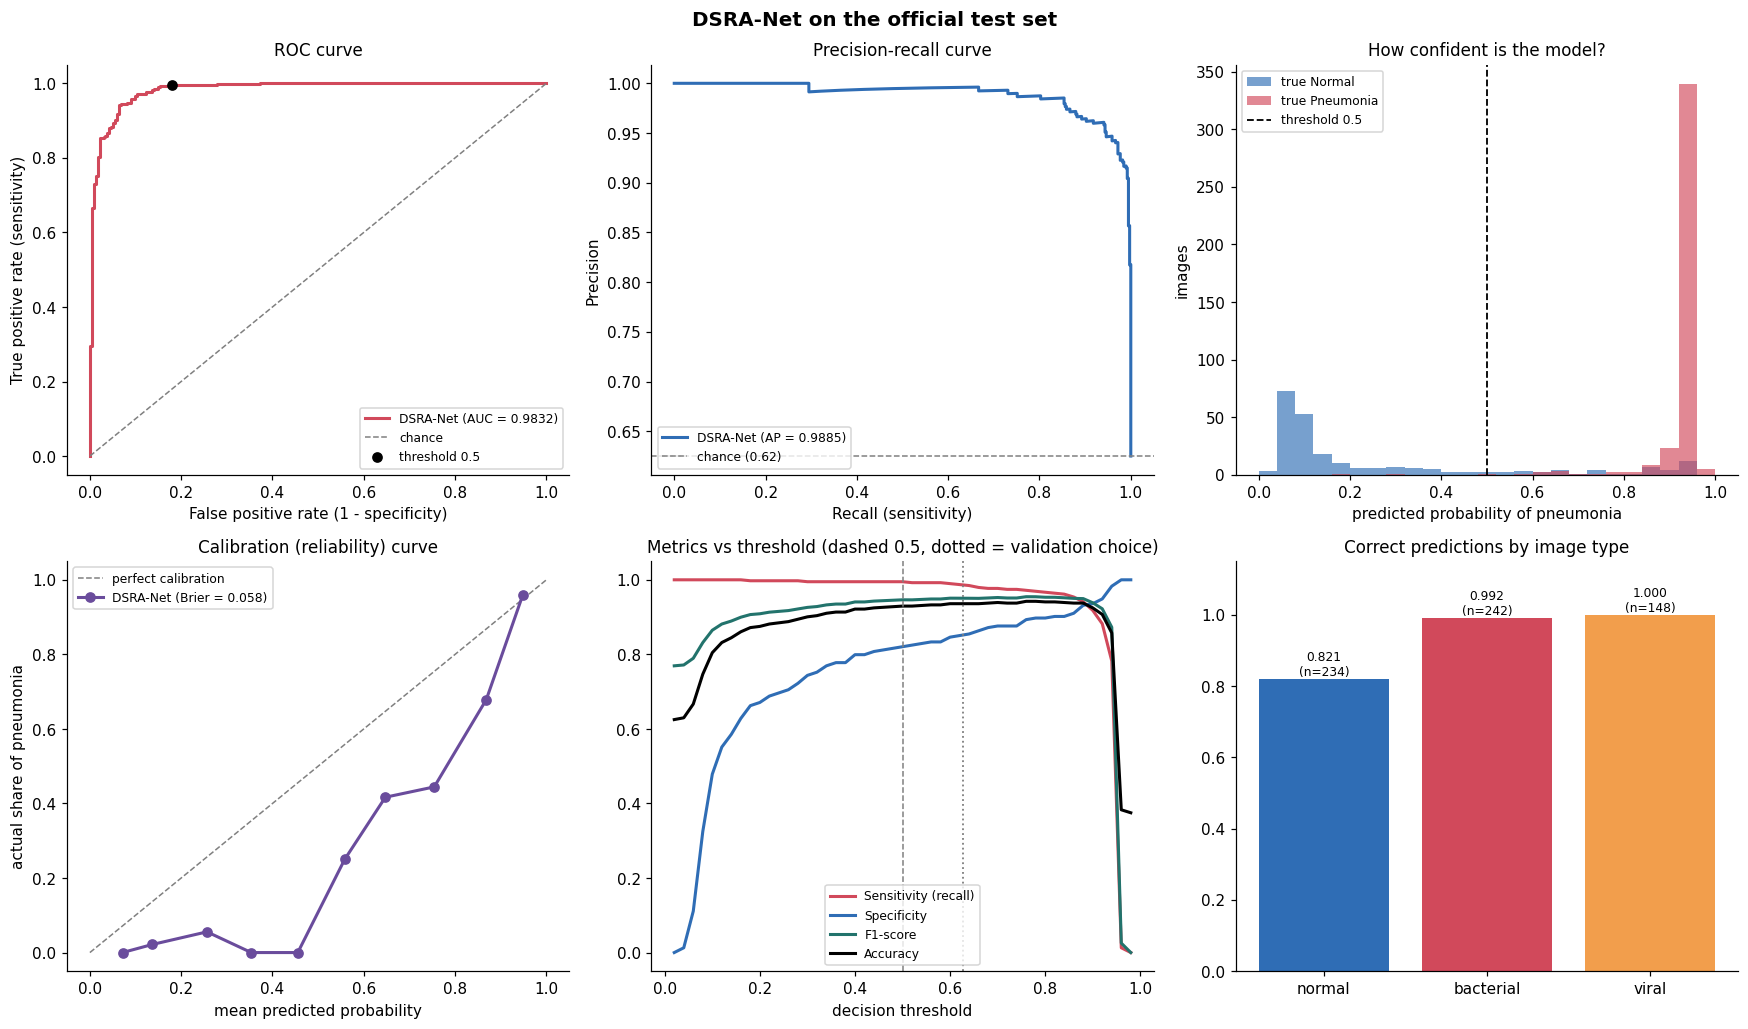

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))

fpr, tpr, _ = roc_curve(y_test, p_test)
ax = axes[0, 0]
ax.plot(fpr, tpr, color=C_PNEU, lw=2, label=f"DSRA-Net (AUC = {m_test['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="chance")
ax.scatter([1 - m_test["Specificity"]], [m_test["Sensitivity (recall)"]], color="black", zorder=3,
           label="threshold 0.5")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curve")
ax.legend(loc="lower right", fontsize=8)

prec_c, rec_c, _ = precision_recall_curve(y_test, p_test)
ax = axes[0, 1]
ax.plot(rec_c, prec_c, color=C_NORMAL, lw=2, label=f"DSRA-Net (AP = {m_test['PR-AUC (AP)']:.4f})")
ax.axhline(y_test.mean(), color="grey", ls="--", lw=1, label=f"chance ({y_test.mean():.2f})")
ax.set_xlabel("Recall (sensitivity)")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curve")
ax.legend(loc="lower left", fontsize=8)

ax = axes[0, 2]
bins = np.linspace(0, 1, 26)
ax.hist(p_test[y_test == 0], bins=bins, alpha=0.65, color=C_NORMAL, label="true Normal")
ax.hist(p_test[y_test == 1], bins=bins, alpha=0.65, color=C_PNEU, label="true Pneumonia")
ax.axvline(THRESHOLD, color="black", ls="--", lw=1.2, label="threshold 0.5")
ax.set_xlabel("predicted probability of pneumonia")
ax.set_ylabel("images")
ax.set_title("How confident is the model?")
ax.legend(fontsize=8)

ax = axes[1, 0]
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="uniform")
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="perfect calibration")
ax.plot(mean_pred, frac_pos, color="#6A4C9C", marker="o", lw=2, label=f"DSRA-Net (Brier = {m_test['Brier score']:.3f})")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("actual share of pneumonia")
ax.set_title("Calibration (reliability) curve")
ax.legend(fontsize=8)

ax = axes[1, 1]
ths = np.linspace(0.02, 0.98, 49)
curves = {k: [] for k in ["Sensitivity (recall)", "Specificity", "F1-score", "Accuracy"]}
for t in ths:
    mt = binary_metrics(y_test, p_test, t)
    for k in curves:
        curves[k].append(mt[k])
for (k, v), col in zip(curves.items(), [C_PNEU, C_NORMAL, "#22736C", "black"]):
    ax.plot(ths, v, lw=2, color=col, label=k)
ax.axvline(THRESHOLD, color="grey", ls="--", lw=1)
ax.axvline(THR_VAL, color="grey", ls=":", lw=1.2)
ax.set_xlabel("decision threshold")
ax.set_title("Metrics vs threshold (dashed 0.5, dotted = validation choice)")
ax.legend(fontsize=8)

ax = axes[1, 2]
types = df.loc[te_idx, "type"].to_numpy()
order = [t for t in ["normal", "bacterial", "viral", "unknown"] if (types == t).any()]
acc_type = [np.mean(y_pred[types == t] == y_test[types == t]) for t in order]
bars = ax.bar(order, acc_type, color=[{"normal": C_NORMAL, "bacterial": C_PNEU, "viral": C_VIRAL,
                                       "unknown": "grey"}[t] for t in order])
ax.bar_label(bars, labels=[f"{v:.3f}\n(n={int((types == t).sum())})" for v, t in zip(acc_type, order)], fontsize=8)
ax.set_ylim(0, 1.15)
ax.set_title("Correct predictions by image type")

fig.suptitle("DSRA-Net on the official test set", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "08_test_analysis")

Misclassified test images: 44 (missed pneumonia: 2, false alarms on Normal: 42)


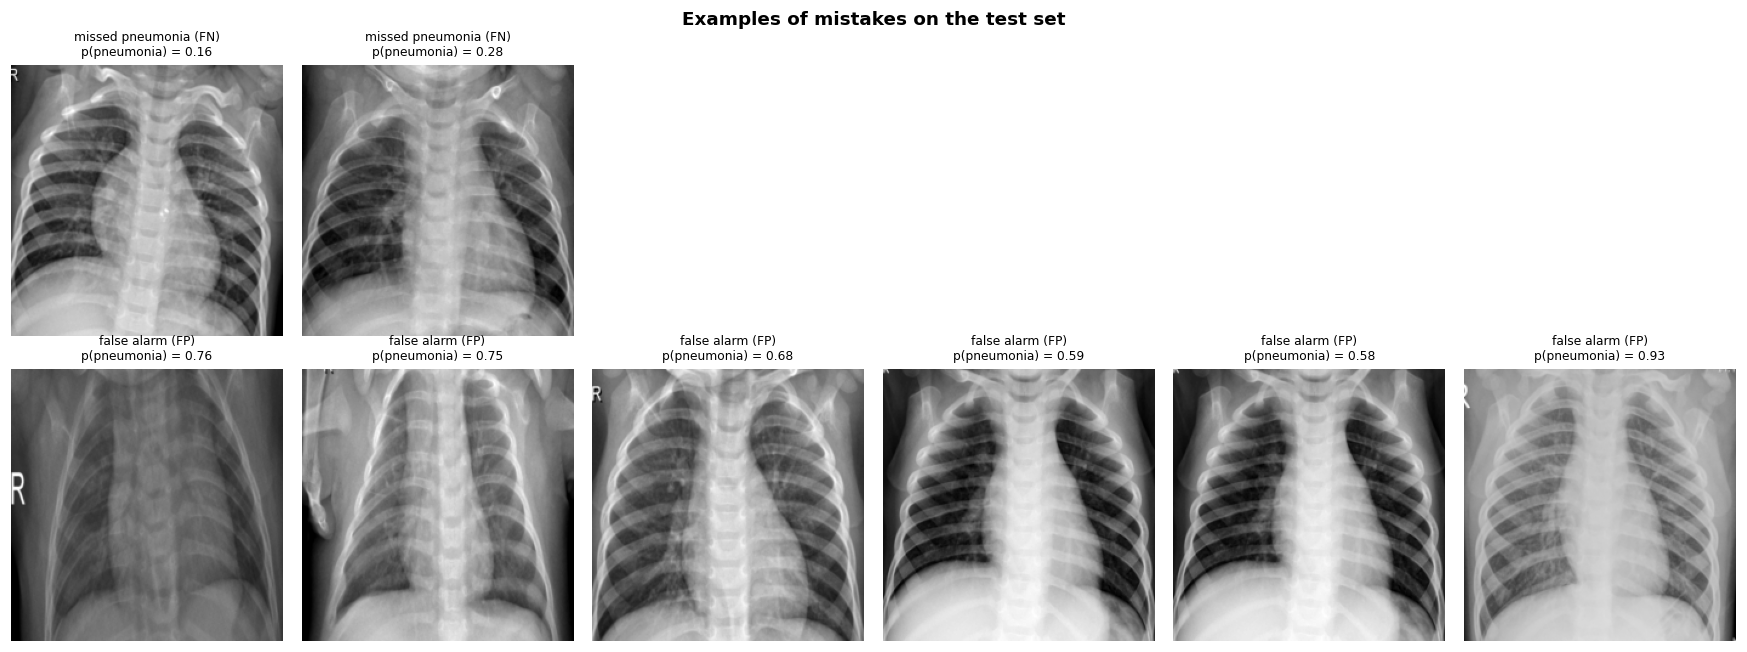

In [16]:
wrong = np.where(y_pred != y_test)[0]
fn_i = [i for i in wrong if y_test[i] == 1][:6]
fp_i = [i for i in wrong if y_test[i] == 0][:6]
print(f"Misclassified test images: {len(wrong)} (missed pneumonia: {int(np.sum((y_test == 1) & (y_pred == 0)))}, "
      f"false alarms on Normal: {int(np.sum((y_test == 0) & (y_pred == 1)))})")
if len(wrong):
    fig, axes = plt.subplots(2, 6, figsize=(16, 6))
    for r, (lst, lab) in enumerate([(fn_i, "missed pneumonia (FN)"), (fp_i, "false alarm (FP)")]):
        for c in range(6):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(lst):
                i = lst[c]
                ax.imshow(X_all[te_idx[i], ..., 0], cmap="gray")
                ax.set_title(f"{lab}\np(pneumonia) = {p_test[i]:.2f}", fontsize=8)
    fig.suptitle("Examples of mistakes on the test set", fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "09_misclassified_examples")

## 8. Intermediate outputs of every block
We pass one **Normal** and one **Pneumonia** test image (correctly classified ones are picked) through the network and show what each block produces.
Sections 8–11 use the single model with the lowest validation loss (no TTA), so every number shown belongs to that one network.
Colour maps show the **average over all channels** of a block's output (bright = strong response); the grids show single channels.
- **Stem** → **(b) DSG block**: branch A (3×3), branch B (5×5), the gate `g`, and the output `Z = g·A + (1 − g)·B`
- **(c) Res-SE blocks**: main path, after **(d)** SE, shortcut, output, and after max-pooling
- **(d) SE attention**: the squeeze values and the learned channel weights `s`
- **Head**: the 256 GAP values, the 128 FC values and the final probability

In [17]:
PROBE = {"stem": "stem_relu", "dsg_A": "dsg_A_relu", "dsg_B": "dsg_B_relu", "dsg_gate": "dsg_gate",
         "dsg_Z": "dsg_out", "dsg_pool": "dsg_pool", "gap": "head_gap", "fc": "head_fc", "prob": "output"}
for i in (1, 2, 3):
    PROBE.update({f"rs{i}_in": "dsg_pool" if i == 1 else f"rs{i - 1}_pool",
                  f"rs{i}_main": f"rs{i}_c2_bn", f"rs{i}_squeeze": f"rs{i}_se_squeeze",
                  f"rs{i}_se_w": f"rs{i}_se_weights", f"rs{i}_se_out": f"rs{i}_se_scale",
                  f"rs{i}_short": f"rs{i}_short_bn", f"rs{i}_out": f"rs{i}_out", f"rs{i}_pool": f"rs{i}_pool"})
layer_order = [l.name for l in model.layers]
probe_layers = sorted(set(PROBE.values()), key=layer_order.index)
probe = keras.Model(model.inputs, [model.get_layer(n).output for n in probe_layers])


def run_probe(x):
    outs = probe.predict(x, verbose=0)
    outs = outs if isinstance(outs, (list, tuple)) else [outs]
    by_layer = dict(zip(probe_layers, outs))
    return {k: np.asarray(by_layer[v]) for k, v in PROBE.items()}


p_ana = predict_probs(model, te_idx, tta=False)             # predictions of the analysed single model
y_ana = (p_ana >= THRESHOLD).astype(int)
print(f"Analysed model (model {best_k + 1}) alone, no TTA: test accuracy {np.mean(y_ana == y_test):.4f}")


def pick_example(label):
    ok = np.where((y_test == label) & (y_ana == label))[0]
    cand = ok if len(ok) else np.where(y_test == label)[0]
    return int(cand[np.argmin(np.abs(p_ana[cand] - np.median(p_ana[cand])))])


ex_pos = [pick_example(0), pick_example(1)]                  # positions inside the test set
ex_names = ["Normal", "Pneumonia"]
x_ex = to_float(te_idx[ex_pos])
acts = run_probe(x_ex)
for n, pidx in zip(ex_names, ex_pos):
    ok = "correct" if y_ana[pidx] == y_test[pidx] else "misclassified (no correct example of this class)"
    print(f"{n} example: {df.loc[te_idx[pidx], 'filename']}  ->  p(pneumonia) = {p_ana[pidx]:.3f}  [{ok}]")


def mean_map(a):
    return a.mean(axis=-1)


def show(ax, img, title, cmap="magma", symmetric=False):
    if symmetric:
        v = float(np.abs(img).max()) or 1.0
        ax.imshow(img, cmap=cmap, vmin=-v, vmax=v)
    else:
        ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=8.5)
    ax.axis("off")

Analysed model (model 3) alone, no TTA: test accuracy 0.9391
Normal example: IM-0033-0001-0001.jpeg  ->  p(pneumonia) = 0.069  [correct]
Pneumonia example: person1663_virus_2876.jpeg  ->  p(pneumonia) = 0.950  [correct]


I0000 00:00:1790242016.118346     138 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


### 8.1 Stem and (b) Dual-Scale Gate block

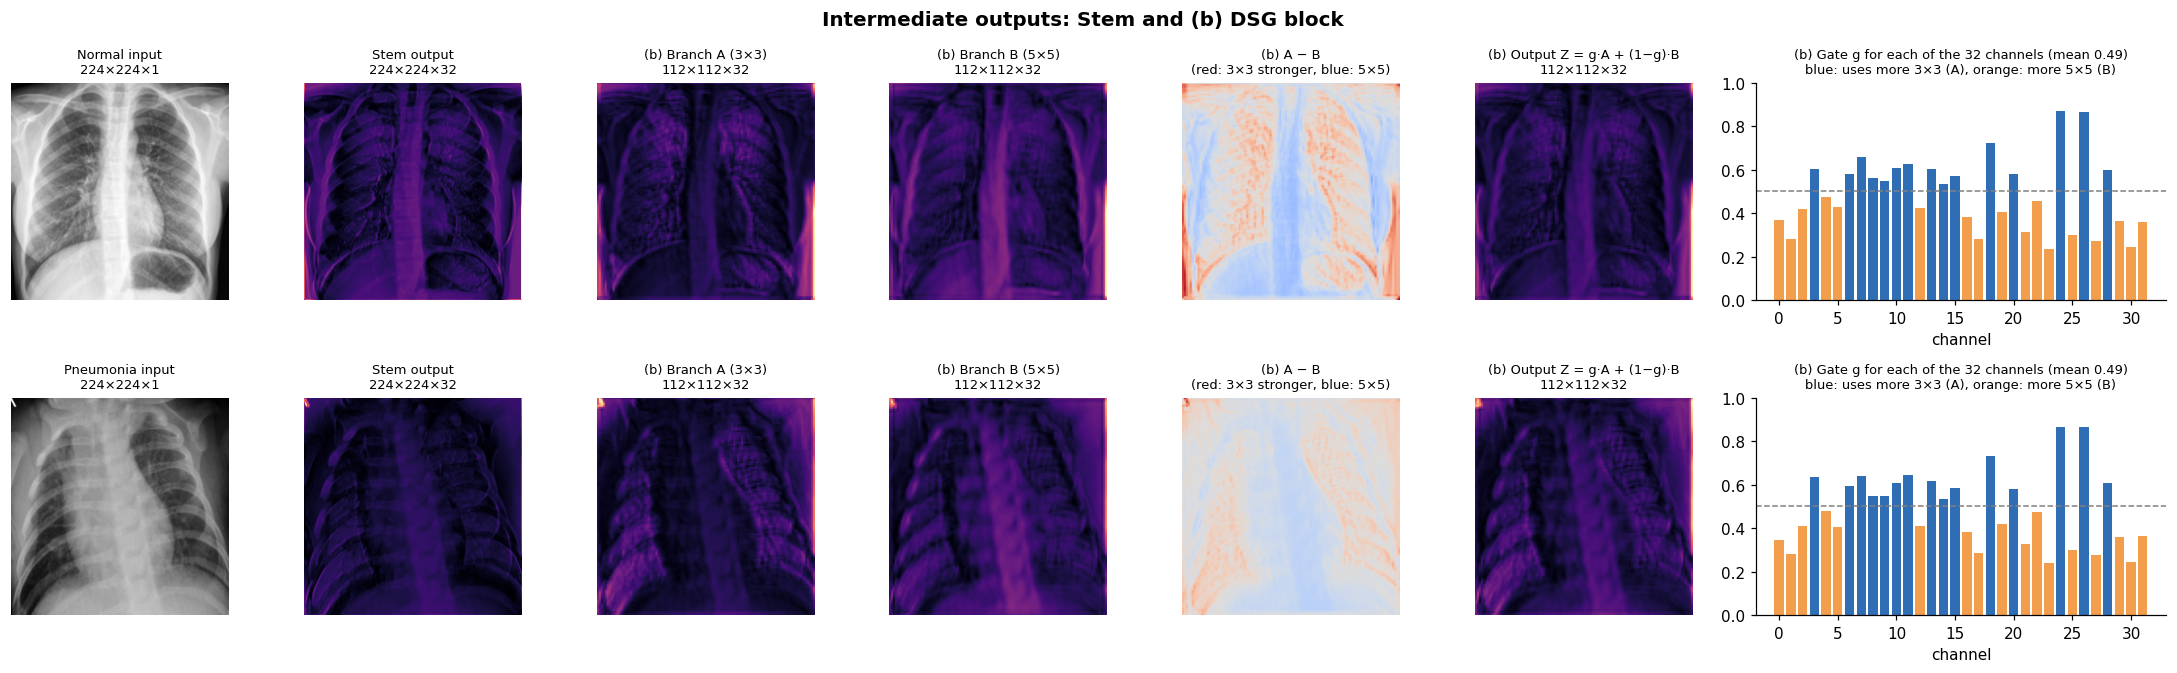

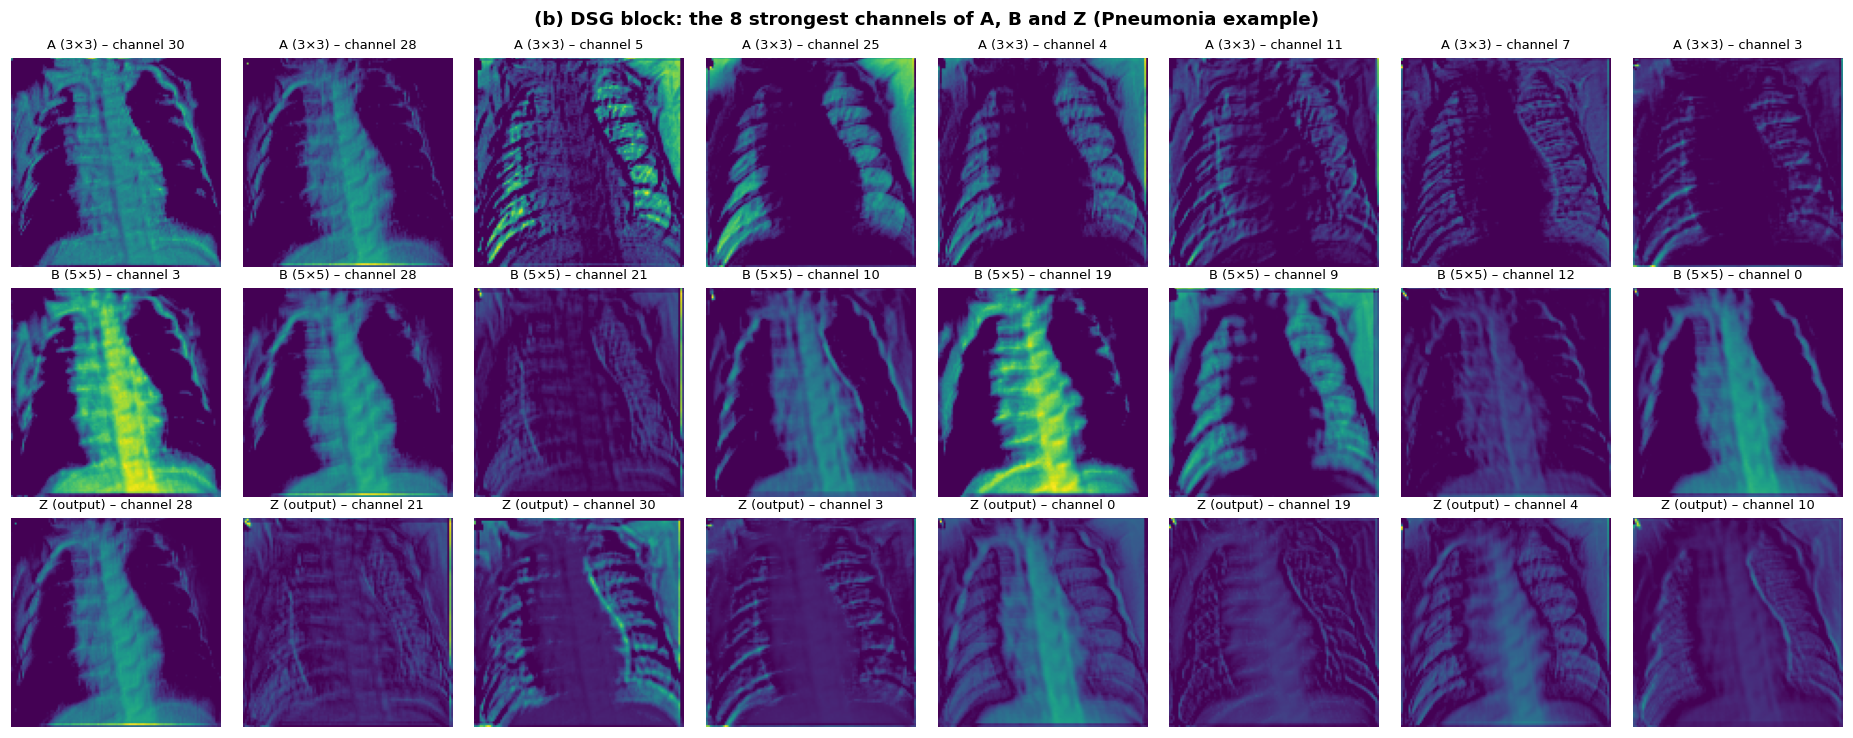

In [19]:
fig = plt.figure(figsize=(20, 6.2))
gs = fig.add_gridspec(2, 7, width_ratios=[1, 1, 1, 1, 1, 1, 1.7])
for r, name in enumerate(ex_names):
    a = {k: v[r] for k, v in acts.items()}
    panels = [(x_ex[r, ..., 0], f"{name} input\n{shp(x_ex[r])}", "gray", False),
              (mean_map(a["stem"]), f"Stem output\n{shp(a['stem'])}", "magma", False),
              (mean_map(a["dsg_A"]), f"(b) Branch A (3×3)\n{shp(a['dsg_A'])}", "magma", False),
              (mean_map(a["dsg_B"]), f"(b) Branch B (5×5)\n{shp(a['dsg_B'])}", "magma", False),
              (mean_map(a["dsg_A"] - a["dsg_B"]), "(b) A − B\n(red: 3×3 stronger, blue: 5×5)", "coolwarm", True),
              (mean_map(a["dsg_Z"]), f"(b) Output Z = g·A + (1−g)·B\n{shp(a['dsg_Z'])}", "magma", False)]
    for c, (img, title, cmap, sym) in enumerate(panels):
        show(fig.add_subplot(gs[r, c]), img, title, cmap, sym)
    ax = fig.add_subplot(gs[r, 6])
    g = a["dsg_gate"]
    ax.bar(np.arange(len(g)), g, color=np.where(g >= 0.5, C_NORMAL, C_VIRAL))
    ax.axhline(0.5, color="grey", ls="--", lw=1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("channel")
    ax.set_title(f"(b) Gate g for each of the {len(g)} channels (mean {g.mean():.2f})\n"
                 "blue: uses more 3×3 (A), orange: more 5×5 (B)", fontsize=8.5)
fig.suptitle("Intermediate outputs: Stem and (b) DSG block", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "10_intermediate_stem_dsg")

a = {k: v[1] for k, v in acts.items()}
fig, axes = plt.subplots(3, 8, figsize=(17, 6.8))
for r, (key, lab) in enumerate([("dsg_A", "A (3×3)"), ("dsg_B", "B (5×5)"), ("dsg_Z", "Z (output)")]):
    top = np.argsort(a[key].mean(axis=(0, 1)))[::-1][:8]
    for c, ch in enumerate(top):
        show(axes[r, c], a[key][..., ch], f"{lab} – channel {ch}", "viridis")
fig.suptitle("(b) DSG block: the 8 strongest channels of A, B and Z (Pneumonia example)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "10b_dsg_channels_pneumonia")

### 8.2 (c) Res-SE blocks

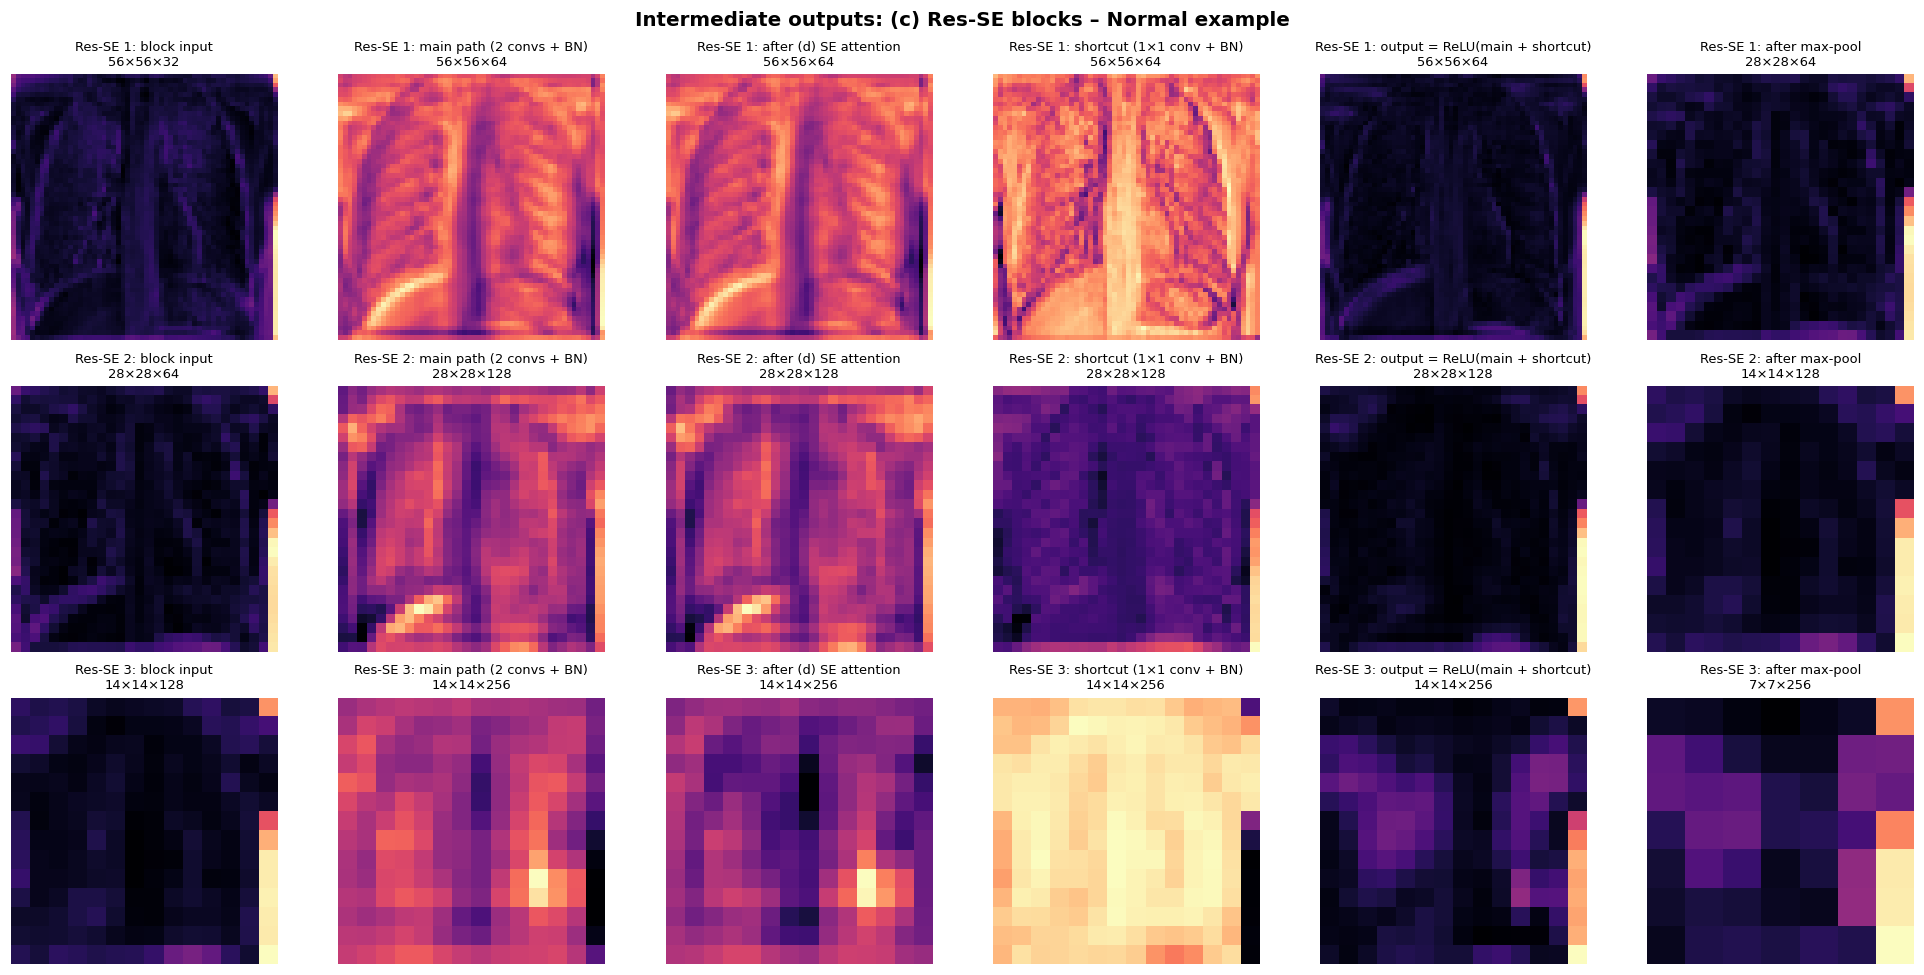

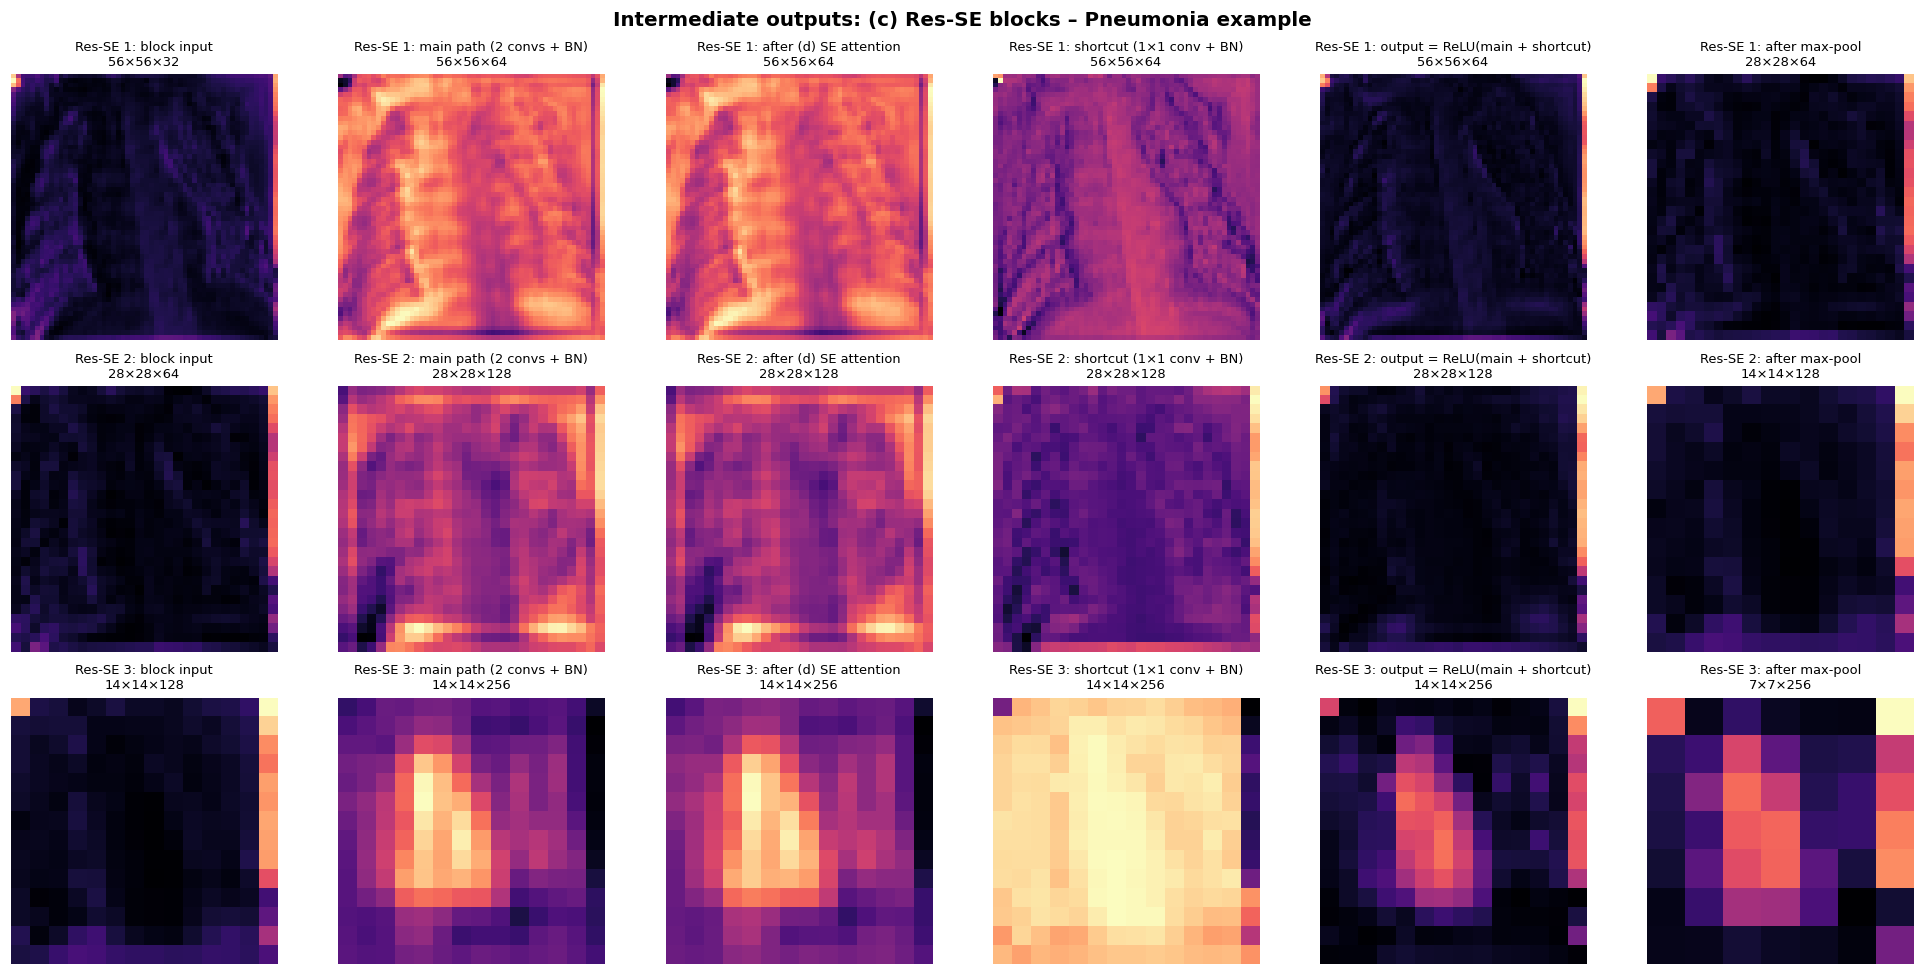

In [20]:
for s_i, name in enumerate(ex_names):
    a = {k: v[s_i] for k, v in acts.items()}
    fig, axes = plt.subplots(3, 6, figsize=(18, 9))
    for b in range(3):
        i = b + 1
        cols = [(f"rs{i}_in", "block input"), (f"rs{i}_main", "main path (2 convs + BN)"),
                (f"rs{i}_se_out", "after (d) SE attention"), (f"rs{i}_short", "shortcut (1×1 conv + BN)"),
                (f"rs{i}_out", "output = ReLU(main + shortcut)"), (f"rs{i}_pool", "after max-pool")]
        for c, (key, lab) in enumerate(cols):
            show(axes[b, c], mean_map(a[key]), f"Res-SE {i}: {lab}\n{shp(a[key])}")
    fig.suptitle(f"Intermediate outputs: (c) Res-SE blocks – {name} example", fontsize=13, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, f"11_intermediate_resse_{name.lower()}")

### 8.3 (d) SE attention and the classifier head

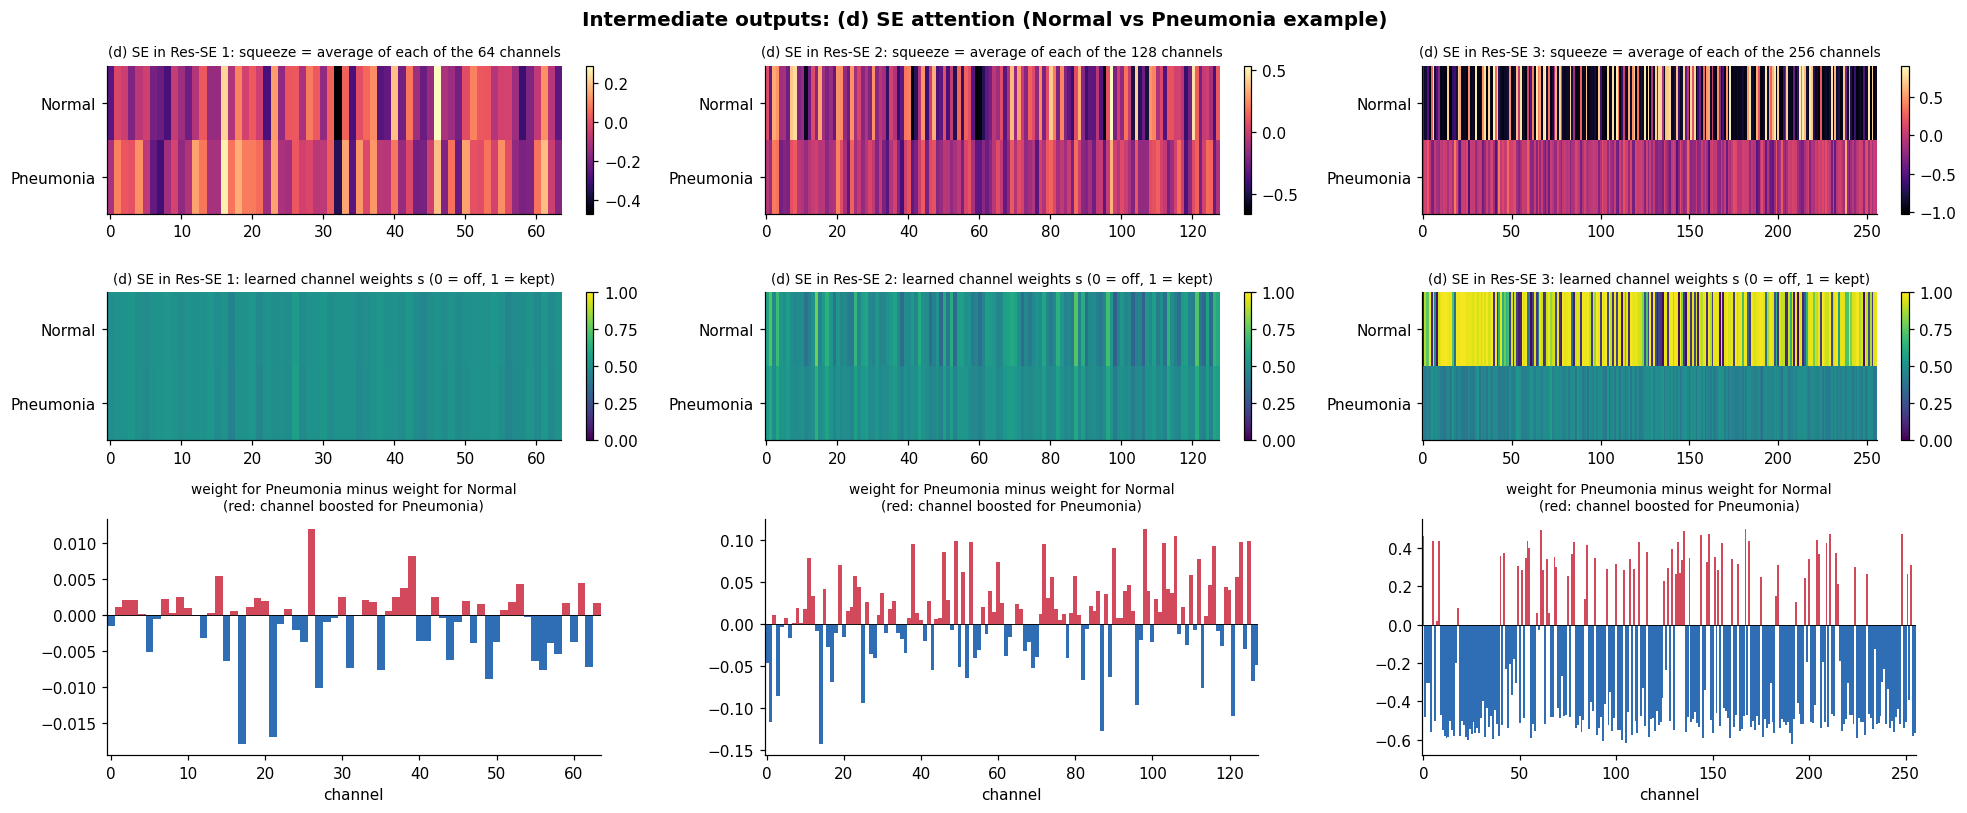

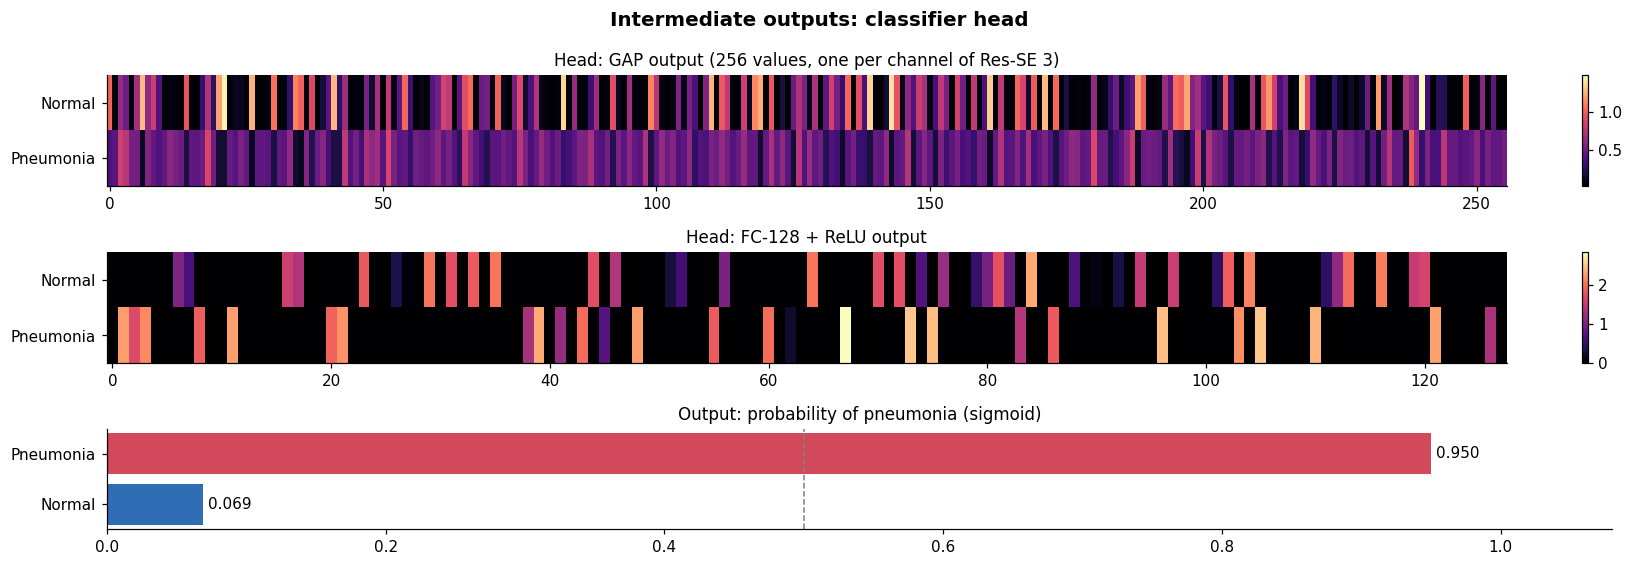

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(18, 7.5), gridspec_kw={"height_ratios": [1, 1, 1.6]})
for b in range(3):
    i = b + 1
    z, s = acts[f"rs{i}_squeeze"], acts[f"rs{i}_se_w"]
    n_ch = s.shape[1]
    im = axes[0, b].imshow(z, aspect="auto", cmap="magma", interpolation="nearest")
    axes[0, b].set_yticks([0, 1], ex_names)
    axes[0, b].set_title(f"(d) SE in Res-SE {i}: squeeze = average of each of the {n_ch} channels", fontsize=9)
    fig.colorbar(im, ax=axes[0, b], fraction=0.03)
    im = axes[1, b].imshow(s, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    axes[1, b].set_yticks([0, 1], ex_names)
    axes[1, b].set_title(f"(d) SE in Res-SE {i}: learned channel weights s (0 = off, 1 = kept)", fontsize=9)
    fig.colorbar(im, ax=axes[1, b], fraction=0.03)
    diff = s[1] - s[0]
    axes[2, b].bar(np.arange(n_ch), diff, width=1.0, color=np.where(diff >= 0, C_PNEU, C_NORMAL))
    axes[2, b].axhline(0, color="black", lw=0.6)
    axes[2, b].set_xlim(-0.5, n_ch - 0.5)
    axes[2, b].set_xlabel("channel")
    axes[2, b].set_title("weight for Pneumonia minus weight for Normal\n(red: channel boosted for Pneumonia)",
                         fontsize=9)
fig.suptitle("Intermediate outputs: (d) SE attention (Normal vs Pneumonia example)", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "12_intermediate_se_attention")

fig, axes = plt.subplots(3, 1, figsize=(15, 5.2), gridspec_kw={"height_ratios": [1, 1, 0.9]})
im0 = axes[0].imshow(acts["gap"], aspect="auto", cmap="magma")
axes[0].set_yticks([0, 1], ex_names)
axes[0].set_title(f"Head: GAP output ({acts['gap'].shape[1]} values, one per channel of Res-SE 3)")
fig.colorbar(im0, ax=axes[0], fraction=0.02)
im1 = axes[1].imshow(acts["fc"], aspect="auto", cmap="magma")
axes[1].set_yticks([0, 1], ex_names)
axes[1].set_title(f"Head: FC-{acts['fc'].shape[1]} + ReLU output")
fig.colorbar(im1, ax=axes[1], fraction=0.02)
probs = acts["prob"].ravel()
bars = axes[2].barh(ex_names, probs, color=[C_NORMAL, C_PNEU])
axes[2].bar_label(bars, labels=[f"{v:.3f}" for v in probs], padding=3)
axes[2].axvline(THRESHOLD, color="grey", ls="--", lw=1)
axes[2].set_xlim(0, 1.08)
axes[2].set_title("Output: probability of pneumonia (sigmoid)")
fig.suptitle("Intermediate outputs: classifier head", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "13_intermediate_head")

## 9. What the gate and the SE attention learned (whole test set)
- **Gate g (b):** above 0.5 means the channel relies more on the 3×3 view (fine detail), below 0.5 more on the 5×5 view (wider patches).
- **SE weights s (d):** which channels each Res-SE block turns up or down, averaged per class.
- **t-SNE / PCA:** the 256 GAP features of every test image squeezed to 2-D; well-separated colours mean the network found features that separate the classes.

Mean gate g: Normal 0.485 | Pneumonia 0.486 | Mann-Whitney U p = 3.08e-09


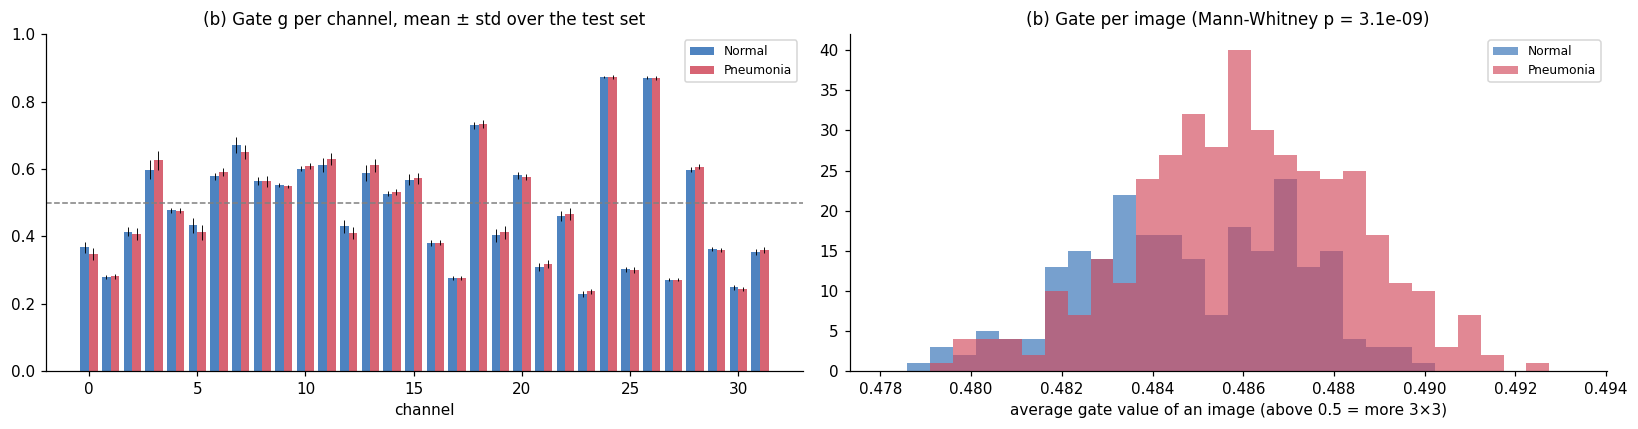

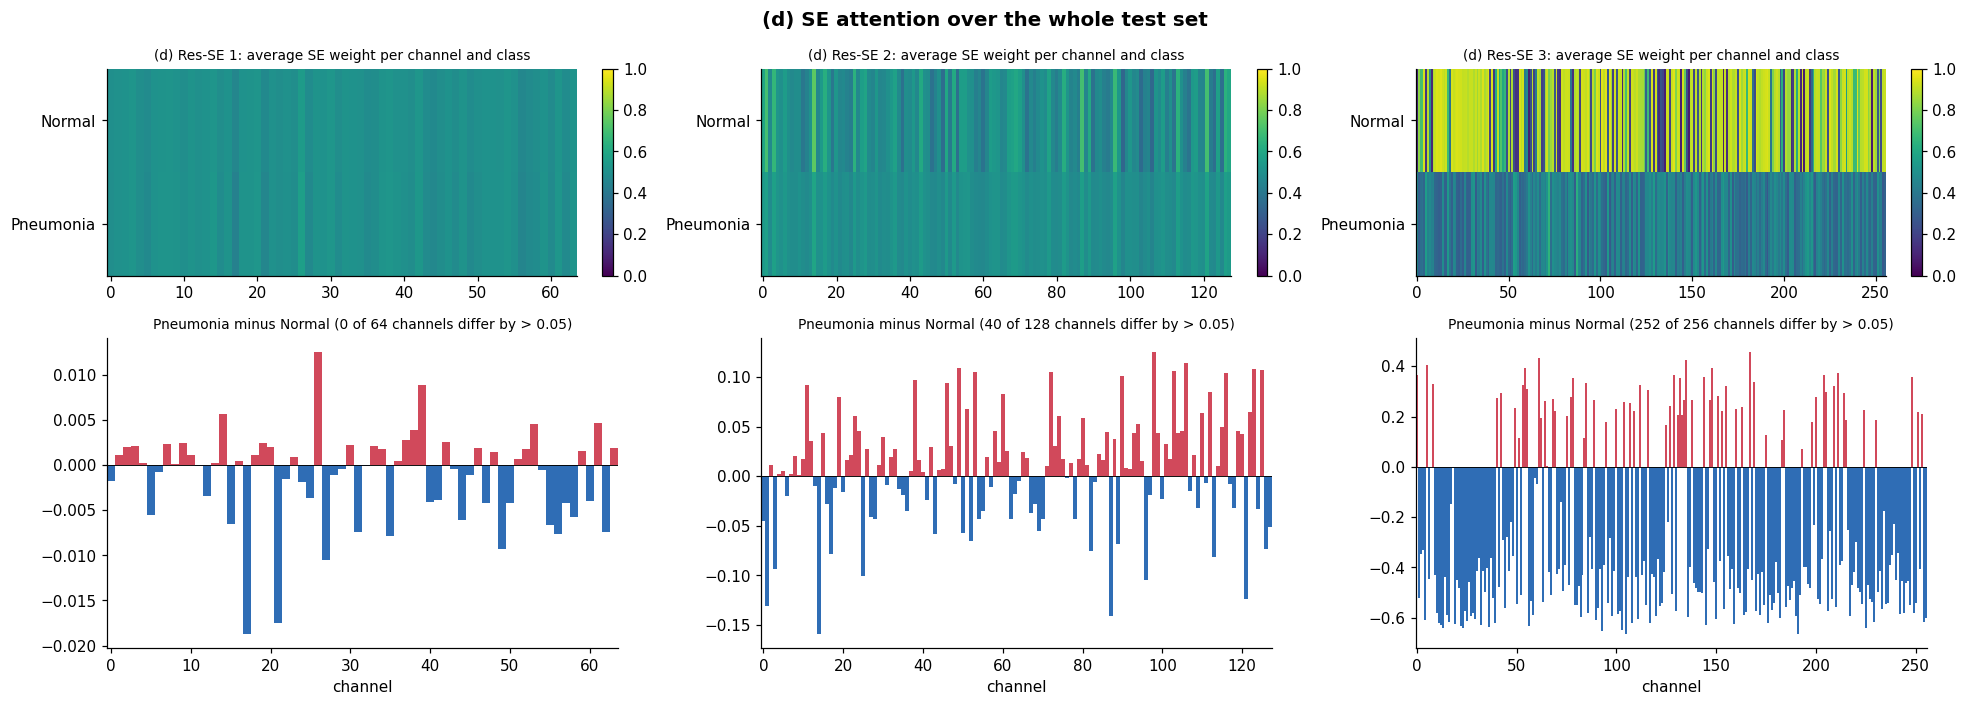

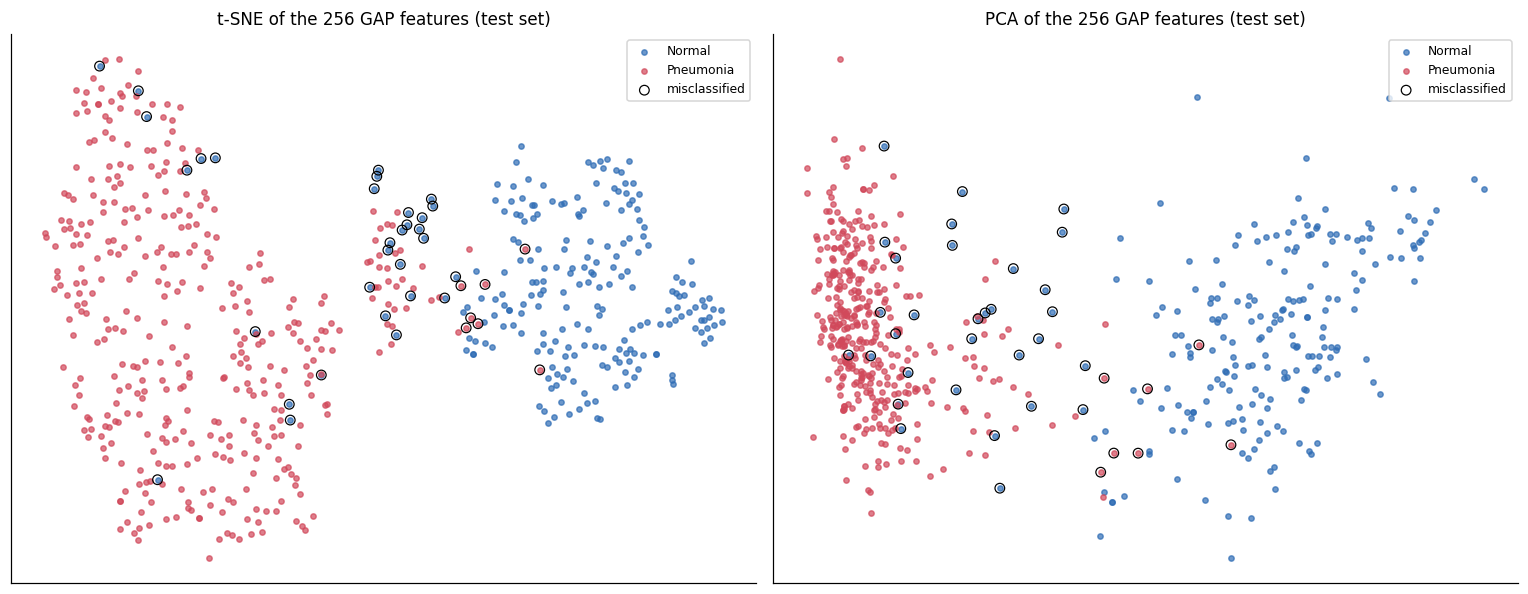

In [22]:
stat_layers = ["dsg_gate", "rs1_se_weights", "rs2_se_weights", "rs3_se_weights", "head_gap"]
stat_model = keras.Model(model.inputs, [model.get_layer(n).output for n in stat_layers])
G, S1, S2, S3, FEAT = [np.asarray(o) for o in stat_model.predict(make_ds(te_idx, False), verbose=0)]

g_img = G.mean(axis=1)
stat, pval = mannwhitneyu(g_img[y_test == 0], g_img[y_test == 1]) if len(np.unique(y_test)) == 2 else (np.nan, np.nan)
print(f"Mean gate g: Normal {g_img[y_test == 0].mean():.3f} | Pneumonia {g_img[y_test == 1].mean():.3f} "
      f"| Mann-Whitney U p = {pval:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
ch = np.arange(G.shape[1])
for off, lab, col in [(-0.2, 0, C_NORMAL), (0.2, 1, C_PNEU)]:
    sel = G[y_test == lab]
    axes[0].bar(ch + off, sel.mean(axis=0), 0.4, yerr=sel.std(axis=0), color=col, alpha=0.85,
                error_kw={"lw": 0.6}, label=CLASS_NAMES[lab])
axes[0].axhline(0.5, color="grey", ls="--", lw=1)
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("channel")
axes[0].set_title("(b) Gate g per channel, mean ± std over the test set")
axes[0].legend(fontsize=8)
lo, hi = float(g_img.min()), float(g_img.max())
pad = max(1e-3, 0.05 * (hi - lo))
bins = np.linspace(lo - pad, hi + pad, 31)                      # bins follow the data range
axes[1].hist(g_img[y_test == 0], bins=bins, alpha=0.65, color=C_NORMAL, label="Normal")
axes[1].hist(g_img[y_test == 1], bins=bins, alpha=0.65, color=C_PNEU, label="Pneumonia")
if lo - pad <= 0.5 <= hi + pad:
    axes[1].axvline(0.5, color="grey", ls="--", lw=1)
axes[1].set_xlabel("average gate value of an image (above 0.5 = more 3×3)")
axes[1].set_title(f"(b) Gate per image (Mann-Whitney p = {pval:.1e})")
axes[1].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "14_gate_analysis_test")

fig, axes = plt.subplots(2, 3, figsize=(18, 6.5), gridspec_kw={"height_ratios": [1, 1.5]})
for b, (S, i) in enumerate(zip([S1, S2, S3], [1, 2, 3])):
    means = np.stack([S[y_test == 0].mean(axis=0), S[y_test == 1].mean(axis=0)])
    im = axes[0, b].imshow(means, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    axes[0, b].set_yticks([0, 1], CLASS_NAMES)
    axes[0, b].set_title(f"(d) Res-SE {i}: average SE weight per channel and class", fontsize=9)
    fig.colorbar(im, ax=axes[0, b], fraction=0.03)
    diff = means[1] - means[0]
    n_big = int(np.sum(np.abs(diff) > 0.05))
    axes[1, b].bar(np.arange(len(diff)), diff, width=1.0, color=np.where(diff >= 0, C_PNEU, C_NORMAL))
    axes[1, b].axhline(0, color="black", lw=0.6)
    axes[1, b].set_xlim(-0.5, len(diff) - 0.5)
    axes[1, b].set_xlabel("channel")
    axes[1, b].set_title(f"Pneumonia minus Normal ({n_big} of {len(diff)} channels differ by > 0.05)", fontsize=9)
fig.suptitle("(d) SE attention over the whole test set", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "15_se_weights_test")

perplexity = float(max(5, min(30, (len(FEAT) - 1) // 3)))
emb_tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=SEED).fit_transform(FEAT)
emb_pca = PCA(n_components=2, random_state=SEED).fit_transform(FEAT)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, emb, title in [(axes[0], emb_tsne, "t-SNE"), (axes[1], emb_pca, "PCA")]:
    for lab, col in [(0, C_NORMAL), (1, C_PNEU)]:
        sel = y_test == lab
        ax.scatter(emb[sel, 0], emb[sel, 1], s=12, alpha=0.7, color=col, label=CLASS_NAMES[lab])
    bad = y_ana != y_test
    ax.scatter(emb[bad, 0], emb[bad, 1], s=40, facecolors="none", edgecolors="black", lw=0.8, label="misclassified")
    ax.set_title(f"{title} of the 256 GAP features (test set)")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "16_feature_space_tsne_pca")

## 10. Grad-CAM: where does the model look?
Grad-CAM is **not part of the model**. It is run on the trained model to show which lung regions drove each decision,
using the last Res-SE block (`rs3_out`, 14×14×256). Red = strong influence on the predicted class.

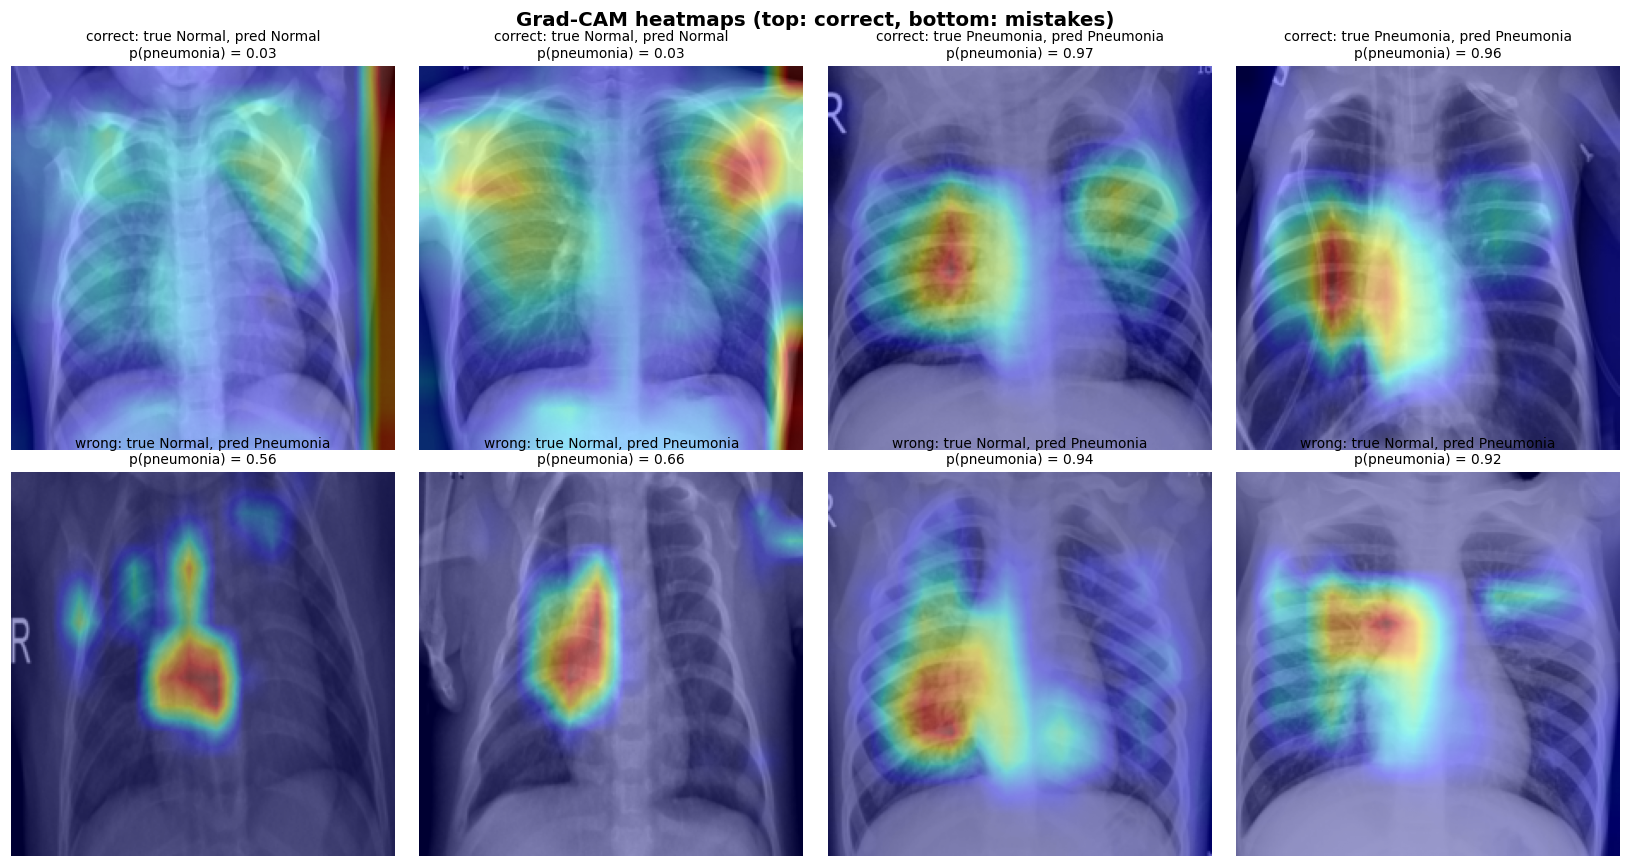

In [23]:
CAM_LAYER = "rs3_out"
grad_model = keras.Model(model.inputs, [model.get_layer(CAM_LAYER).output, model.output])


def grad_cam(img):
    x = tf.convert_to_tensor(img[None].astype("float32"))
    with tf.GradientTape() as tape:
        conv, pred = grad_model(x, training=False)
        p = pred[:, 0]
        target = tf.where(p >= THRESHOLD, p, 1.0 - p)          # explain the predicted class
    grads = tape.gradient(target, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(conv * weights, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE), method="bilinear")[..., 0]
    return np.asarray(cam), float(np.asarray(p)[0])


correct = np.where(y_ana == y_test)[0]
chosen = []
for lab in (0, 1):
    c = correct[y_test[correct] == lab]
    chosen += list(c[np.argsort(-np.abs(p_ana[c] - 0.5))][:2])
wrong = np.where(y_ana != y_test)[0][:4]
rows_ = [("correct", chosen), ("wrong", list(wrong))]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for r, (kind, lst) in enumerate(rows_):
    for c in range(4):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(lst):
            i = int(lst[c])
            img = to_float(te_idx[i:i + 1])[0]
            cam, p = grad_cam(img)
            ax.imshow(img[..., 0], cmap="gray")
            ax.imshow(cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)
            ax.set_title(f"{kind}: true {CLASS_NAMES[y_test[i]]}, pred {CLASS_NAMES[int(p >= THRESHOLD)]}\n"
                         f"p(pneumonia) = {p:.2f}", fontsize=9)
        elif r == 1 and c == 0:
            ax.text(0.5, 0.5, "no misclassified test images", ha="center", va="center")
fig.suptitle("Grad-CAM heatmaps (top: correct, bottom: mistakes)", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "17_gradcam")

## 11. Model size and speed

,DSRA-Net
Parameters (total),1301177.000
Parameters (trainable),1298297.000
"Model size, float32 weights (MB)",5.200
GMACs per image,0.991
"Training time per model, official split (min)",20.700
"GPU latency, 1 image (ms)",3.570
"GPU throughput, batch 32 (images/s)",870.140
"CPU latency, 1 image (ms)",24.890


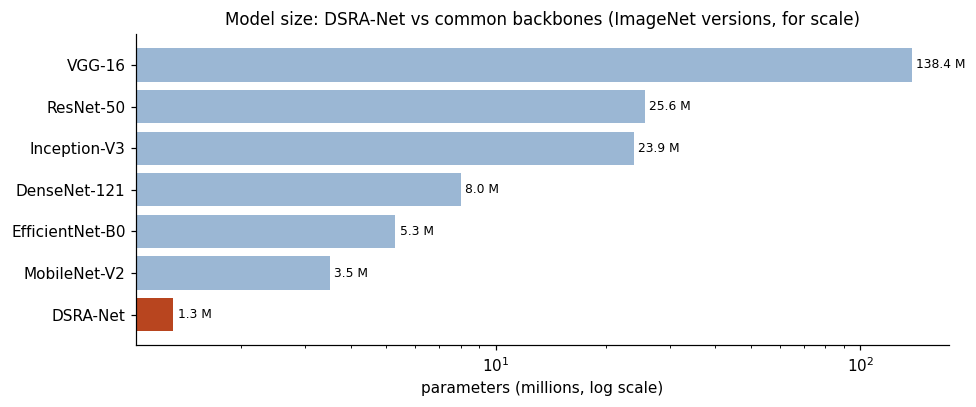

In [24]:
def time_inference(device, batch, reps=30):
    with tf.device(device):
        fn = tf.function(lambda t: model(t, training=False))
        x = tf.constant(to_float(te_idx[:batch]))
        fn(x)
        fn(x)
        t0 = time.perf_counter()
        for _ in range(reps):
            _ = np.asarray(fn(x))
        return (time.perf_counter() - t0) / reps


bs = int(min(32, len(te_idx)))
speed = {}
if gpus:
    speed["GPU latency, 1 image (ms)"] = 1000 * time_inference("/GPU:0", 1)
    speed[f"GPU throughput, batch {bs} (images/s)"] = bs / time_inference("/GPU:0", bs)
speed["CPU latency, 1 image (ms)"] = 1000 * time_inference("/CPU:0", 1, reps=10)

n_trainable = int(np.sum([np.prod([int(d) for d in w.shape]) for w in model.trainable_weights]))
eff = pd.Series({"Parameters (total)": TOTAL_PARAMS, "Parameters (trainable)": n_trainable,
                 "Model size, float32 weights (MB)": round(TOTAL_PARAMS * 4 / 1e6, 2),
                 "GMACs per image": round(costs["MACs"].sum() / 1e9, 3),
                 "Training time per model, official split (min)": round(train_seconds / 60 / len(runs), 1),
                 **{k: round(v, 2) for k, v in speed.items()}}, name="DSRA-Net")
display(eff.to_frame())
save_table(eff.to_frame(), "efficiency", index=True)

ref = pd.Series({"VGG-16": 138.4, "ResNet-50": 25.6, "Inception-V3": 23.9, "DenseNet-121": 8.0,
                 "EfficientNet-B0": 5.3, "MobileNet-V2": 3.5, "DSRA-Net": TOTAL_PARAMS / 1e6}).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(ref.index, ref.values, color=["#B8451F" if k == "DSRA-Net" else "#9BB7D4" for k in ref.index])
ax.bar_label(bars, labels=[f"{v:.1f} M" for v in ref.values], padding=3, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("parameters (millions, log scale)")
ax.set_title("Model size: DSRA-Net vs common backbones (ImageNet versions, for scale)")
fig.tight_layout()
save_fig(fig, "18_model_size_comparison")

## 12. Patient-wise 5-fold cross-validation (all 5,856 images)
All images (train + val + test folders) are pooled and split into 5 folds **by patient**.
Each fold is used once as the test set; the other 4 folds are split again by patient into train (90%) and validation (10%).
A new DSRA-Net is trained from scratch for every fold (one model per fold, with TTA at test time).
This gives a **mean ± standard deviation** over 5 different test sets, which is more reliable than one fixed test set,
and it is not affected by the differences between the official train and test folders. Set `RUN_CV = False` to skip it.

In [25]:
cv_df = None
if RUN_CV:
    sgkf = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    cv_rows, cv_hist, cv_curves = [], [], []
    oof = np.full(len(df), np.nan)
    t_cv = time.time()
    for fold, (pool_i, test_i) in enumerate(sgkf.split(df, df["label"], groups=df["patient"]), start=1):
        keras.backend.clear_session()
        gc.collect()
        keras.utils.set_random_seed(SEED + fold)
        tr_f, va_f = patient_holdout(df.iloc[pool_i], VAL_FRACTION, SEED + fold)
        assert not (set(tr_f["patient"]) | set(va_f["patient"])) & set(df.iloc[test_i]["patient"])
        print(f"\n========== Fold {fold}/{CV_FOLDS}: train {len(tr_f)} | val {len(va_f)} | test {len(test_i)} images ==========")
        m = compile_model(build_dsranet())
        h, sec = train_model(m, tr_f.index.to_numpy(), va_f.index.to_numpy(),
                             class_weights(y_all[tr_f.index.to_numpy()]), f"dsranet_cv_fold{fold}", seed=SEED + fold)
        p = predict_probs(m, test_i)
        oof[test_i] = p
        met = binary_metrics(y_all[test_i], p)
        met.update({"fold": fold, "epochs": len(h), "minutes": round(sec / 60, 1)})
        cv_rows.append(met)
        h["fold"] = fold
        cv_hist.append(h)
        f_fpr, f_tpr, _ = roc_curve(y_all[test_i], p)
        cv_curves.append((f_fpr, f_tpr, met["ROC-AUC"]))
        print(f"Fold {fold}: accuracy {met['Accuracy']:.4f} | sensitivity {met['Sensitivity (recall)']:.4f} | "
              f"specificity {met['Specificity']:.4f} | F1 {met['F1-score']:.4f} | AUC {met['ROC-AUC']:.4f}")
        del m
        gc.collect()
    print(f"\nCross-validation finished in {(time.time() - t_cv) / 60:.1f} min")

    cv_df = pd.DataFrame(cv_rows).set_index("fold")
    main_cols = ["Accuracy", "Balanced accuracy", "Sensitivity (recall)", "Specificity", "Precision (PPV)",
                 "NPV", "F1-score", "MCC", "Cohen's kappa", "ROC-AUC", "PR-AUC (AP)"]
    cv_table = cv_df[main_cols + ["TP", "TN", "FP", "FN", "epochs", "minutes"]].copy()
    cv_table.loc["mean"] = cv_df[main_cols].mean()
    cv_table.loc["std"] = cv_df[main_cols].std(ddof=1)
    display(cv_table.round(4))
    save_table(cv_table.round(6), "cv_metrics_per_fold", index=True)
    save_table(pd.concat(cv_hist), "cv_training_history")
    print("Mean ± std:")
    for k in ["Accuracy", "Sensitivity (recall)", "Specificity", "F1-score", "ROC-AUC"]:
        print(f"  {k:22s} {cv_df[k].mean():.4f} ± {cv_df[k].std(ddof=1):.4f}")
else:
    print("RUN_CV = False -> cross-validation skipped.")


========== Fold 1/5: train 4210 | val 441 | test 1205 images ==========
Epoch 1/60
132/132 - 36s - 274ms/step - accuracy: 0.8204 - auc: 0.8982 - loss: 0.8047 - precision: 0.9348 - recall: 0.8097 - val_accuracy: 0.4694 - val_auc: 0.9742 - val_loss: 1.3773 - val_precision: 1.0000 - val_recall: 0.2733 - learning_rate: 0.0010
Epoch 2/60
132/132 - 23s - 172ms/step - accuracy: 0.8743 - auc: 0.9442 - loss: 0.6901 - precision: 0.9604 - recall: 0.8629 - val_accuracy: 0.6236 - val_auc: 0.9805 - val_loss: 0.9906 - val_precision: 1.0000 - val_recall: 0.4845 - learning_rate: 0.0010
Epoch 3/60
132/132 - 22s - 170ms/step - accuracy: 0.8843 - auc: 0.9531 - loss: 0.6384 - precision: 0.9610 - recall: 0.8766 - val_accuracy: 0.8503 - val_auc: 0.9847 - val_loss: 0.6629 - val_precision: 0.9961 - val_recall: 0.7981 - learning_rate: 0.0010
Epoch 4/60
132/132 - 23s - 173ms/step - accuracy: 0.9048 - auc: 0.9623 - loss: 0.5869 - precision: 0.9647 - recall: 0.9021 - val_accuracy: 0.9161 - val_auc: 0.9861 - val_l

,Accuracy,Balanced accuracy,Sensitivity (recall),Specificity,Precision (PPV),NPV,F1-score,MCC,Cohen's kappa,ROC-AUC,PR-AUC (AP),TP,TN,FP,FN,epochs,minutes
fold,,,,,,,,,,,,,,,,,
1,0.9568,0.9455,0.9696,0.9214,0.9718,0.9156,0.9707,0.8892,0.8892,0.9926,0.9975,860.0,293.0,25.0,27.0,28.0,11.3
2,0.9768,0.9632,0.9929,0.9335,0.9756,0.9801,0.9842,0.9410,0.9405,0.9959,0.9984,841.0,295.0,21.0,6.0,47.0,18.7
3,0.9598,0.9274,0.9976,0.8571,0.9500,0.9923,0.9732,0.8974,0.8932,0.9948,0.9980,817.0,258.0,43.0,2.0,27.0,11.4
4,0.9769,0.9638,0.9921,0.9356,0.9767,0.9776,0.9843,0.9409,0.9404,0.9885,0.9939,879.0,305.0,21.0,7.0,54.0,23.0
5,0.9637,0.9567,0.9724,0.9410,0.9771,0.9294,0.9748,0.9100,0.9099,0.9927,0.9973,811.0,303.0,19.0,23.0,49.0,21.7
mean,0.9668,0.9513,0.9849,0.9177,0.9702,0.9590,0.9774,0.9157,0.9146,0.9929,0.9970,NaN,NaN,NaN,NaN,NaN,NaN
std,0.0095,0.0153,0.0129,0.0346,0.0115,0.0341,0.0064,0.0242,0.0248,0.0028,0.0018,NaN,NaN,NaN,NaN,NaN,NaN


Mean ± std:
  Accuracy               0.9668 ± 0.0095
  Sensitivity (recall)   0.9849 ± 0.0129
  Specificity            0.9177 ± 0.0346
  F1-score               0.9774 ± 0.0064
  ROC-AUC                0.9929 ± 0.0028


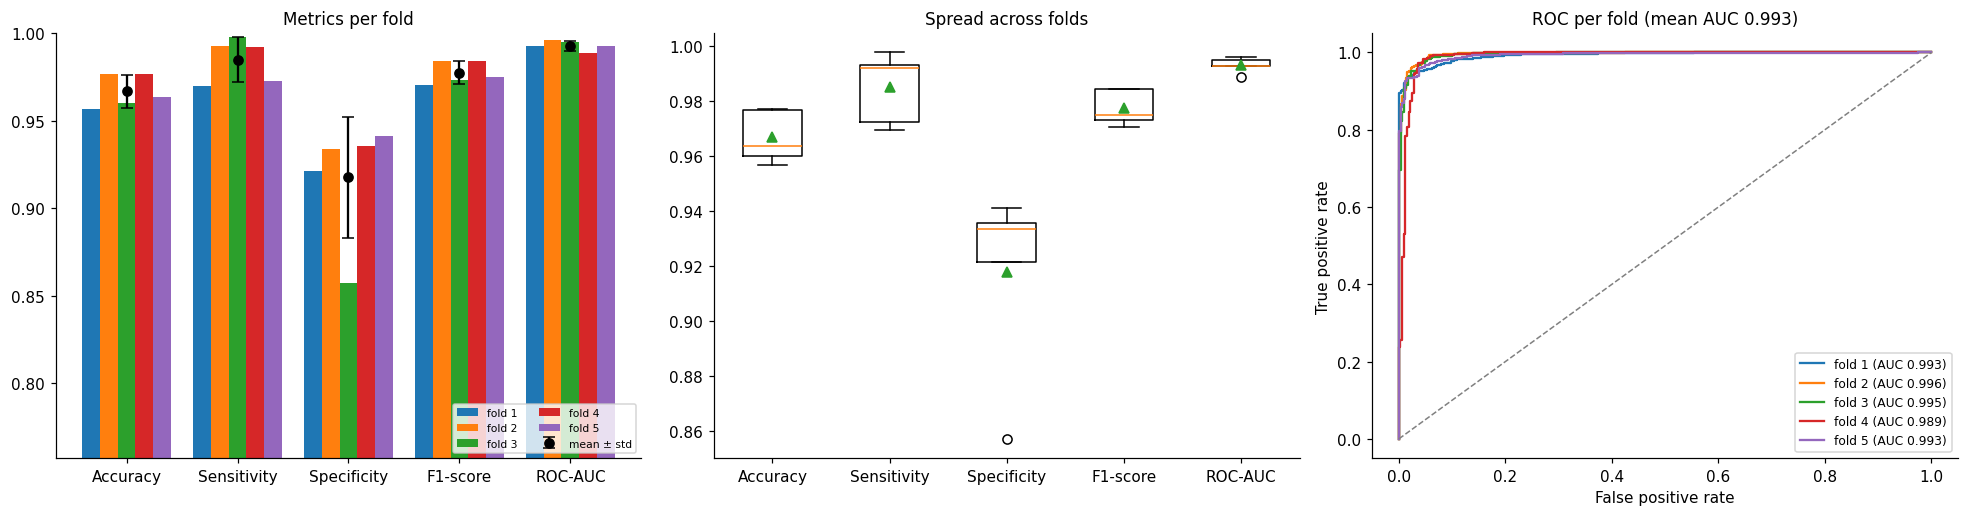

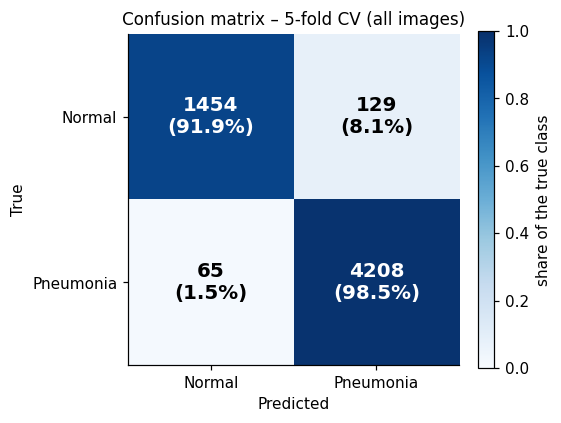

              precision    recall  f1-score   support

      Normal     0.9572    0.9185    0.9375      1583
   Pneumonia     0.9703    0.9848    0.9775      4273

    accuracy                         0.9669      5856
   macro avg     0.9637    0.9516    0.9575      5856
weighted avg     0.9667    0.9669    0.9667      5856



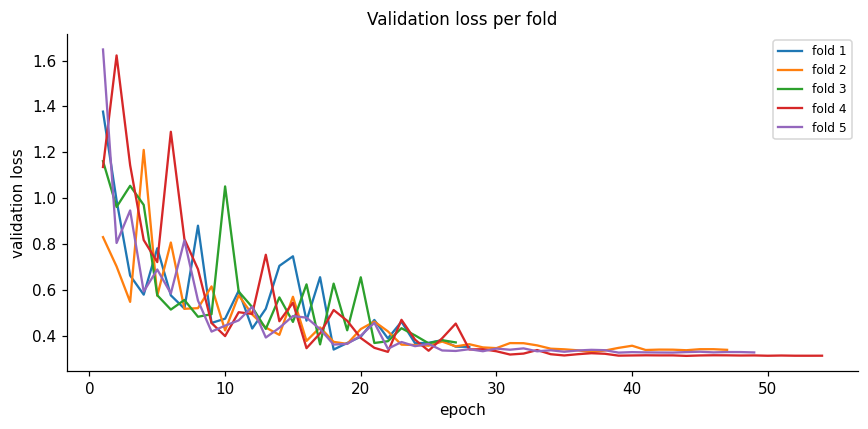

In [26]:
if RUN_CV and cv_df is not None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    keys = ["Accuracy", "Sensitivity (recall)", "Specificity", "F1-score", "ROC-AUC"]
    x = np.arange(len(keys))
    w = 0.8 / len(cv_df)
    for j, (fold, row) in enumerate(cv_df.iterrows()):
        axes[0].bar(x + (j - (len(cv_df) - 1) / 2) * w, row[keys].values.astype(float), w, label=f"fold {fold}")
    axes[0].errorbar(x, cv_df[keys].mean().values, yerr=cv_df[keys].std(ddof=1).values, fmt="ko", capsize=4,
                     label="mean ± std")
    axes[0].set_xticks(x, [k.split(" (")[0] for k in keys])
    axes[0].set_ylim(max(0.0, float(cv_df[keys].values.min()) - 0.1), 1.0)
    axes[0].set_title("Metrics per fold")
    axes[0].legend(fontsize=7, ncol=2, loc="lower right")

    axes[1].boxplot([cv_df[k].values for k in keys], showmeans=True)
    axes[1].set_xticks(np.arange(1, len(keys) + 1), [k.split(" (")[0] for k in keys])
    axes[1].set_title("Spread across folds")

    for (f_fpr, f_tpr, f_auc), fold in zip(cv_curves, cv_df.index):
        axes[2].plot(f_fpr, f_tpr, lw=1.5, label=f"fold {fold} (AUC {f_auc:.3f})")
    axes[2].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
    axes[2].set_xlabel("False positive rate")
    axes[2].set_ylabel("True positive rate")
    axes[2].set_title(f"ROC per fold (mean AUC {cv_df['ROC-AUC'].mean():.3f})")
    axes[2].legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, "19_cv_results")

    oof_pred = (oof >= THRESHOLD).astype(int)
    plot_confusion(y_all, oof_pred, "Confusion matrix – 5-fold CV (all images)", "20_confusion_matrix_cv")
    print(classification_report(y_all, oof_pred, labels=[0, 1], target_names=CLASS_NAMES, digits=4, zero_division=0))
    cv_report = pd.DataFrame(classification_report(y_all, oof_pred, labels=[0, 1], target_names=CLASS_NAMES,
                                                   digits=4, zero_division=0, output_dict=True)).T
    save_table(cv_report.round(6), "classification_report_cv", index=True)

    fig, ax = plt.subplots(figsize=(8, 4))
    for h in cv_hist:
        ax.plot(h["epoch"], h["val_loss"], lw=1.5, label=f"fold {int(h['fold'].iloc[0])}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation loss")
    ax.set_title("Validation loss per fold")
    ax.legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, "21_cv_validation_loss")

## 13. Summary

In [27]:
summary_json = {
    "model": "DSRA-Net v2", "parameters": TOTAL_PARAMS, "GMACs_per_image": round(costs["MACs"].sum() / 1e9, 3),
    "official_test_prediction": ENS_NAME,
    "official_test_threshold_0.5": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_test.items()},
    "official_test_95CI": {k: [round(a, 4), round(b, 4)] for k, (a, b) in ci.items()},
    "official_test_single_models_mean_std": {k: effect_df.iloc[len(steps) - 1][k] for k in KEYS},
    "validation_threshold": round(THR_VAL, 3),
    "bias_check_auc": bias_table.to_dict(orient="index"),
}
if RUN_CV and cv_df is not None:
    summary_json["cv_mean_std"] = {k: [round(float(cv_df[k].mean()), 4), round(float(cv_df[k].std(ddof=1)), 4)]
                                   for k in ["Accuracy", "Sensitivity (recall)", "Specificity", "F1-score", "ROC-AUC"]}
with open(os.path.join(OUT_DIR, "results_summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2, default=str)

if RUN_CV and cv_df is not None:
    print(f"PATIENT-WISE {CV_FOLDS}-FOLD CROSS-VALIDATION, all {len(df)} images (mean ± std)")
    for k, (mu, sd) in summary_json["cv_mean_std"].items():
        print(f"  {k:22s} {mu:.4f} ± {sd:.4f}")
    print()
print(f"OFFICIAL TEST SET ({len(te_idx)} images, {ENS_NAME}, threshold {THRESHOLD})")
for k in ["Accuracy", "Sensitivity (recall)", "Specificity", "Precision (PPV)", "F1-score", "ROC-AUC"]:
    lo, hi = ci.get(k, (float("nan"), float("nan")))
    print(f"  {k:22s} {m_test[k]:.4f}   (95% CI {lo:.4f} - {hi:.4f})")
print("\nSingle models on the official test set (mean ± std):")
for k, v in summary_json["official_test_single_models_mean_std"].items():
    print(f"  {k:22s} {v}")
print(f"\nParameters: {TOTAL_PARAMS:,}")
print("\nSaved files:")
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        print("  ", os.path.relpath(os.path.join(root, f), OUT_DIR))

PATIENT-WISE 5-FOLD CROSS-VALIDATION, all 5856 images (mean ± std)
  Accuracy               0.9668 ± 0.0095
  Sensitivity (recall)   0.9849 ± 0.0129
  Specificity            0.9177 ± 0.0346
  F1-score               0.9774 ± 0.0064
  ROC-AUC                0.9929 ± 0.0028

OFFICIAL TEST SET (624 images, ensemble of 3 + TTA, threshold 0.5)
  Accuracy               0.9295   (95% CI 0.9087 - 0.9487)
  Sensitivity (recall)   0.9949   (95% CI 0.9866 - 1.0000)
  Specificity            0.8205   (95% CI 0.7662 - 0.8689)
  Precision (PPV)        0.9023   (95% CI 0.8747 - 0.9300)
  F1-score               0.9463   (95% CI 0.9308 - 0.9619)
  ROC-AUC                0.9832   (95% CI 0.9727 - 0.9909)

Single models on the official test set (mean ± std):
  Accuracy               0.9231 ± 0.0105
  Sensitivity (recall)   0.9889 ± 0.0078
  Specificity            0.8134 ± 0.0358
  F1-score               0.9415 ± 0.0074
  ROC-AUC                0.9799 ± 0.0011

Parameters: 1,301,177

Saved files:
   results